# Lista 3 — Estatística Bayesiana · 2026/2
**Igor Stellet · Questão 1, 2, 3, 4 e 5**

Este notebook reúne as deduções, os cálculos, as figuras e as tabelas da Lista 3. A ideia é fazer todos os gráficos, tabelas e resultados que entrarão no overleaf. Aqui também terá uma discussão mais por cima de cada questão, no overleaf se encotrará uma discussão mais abrangente de cada um dos itens.

In [1]:
# Imports e configuração: as funções usadas nesta lista ficam no próprio notebook.
from pathlib import Path
import csv
import platform
import numpy as np
import scipy
from scipy import stats, special, integrate
from numpy.polynomial.legendre import leggauss
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.patches import Rectangle
from IPython.display import display, Markdown

%config InlineBackend.figure_format = "retina"
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11,
    "legend.fontsize": 9, "lines.linewidth": 2,
    "grid.alpha": 0.22, "axes.spines.top": False,
    "axes.spines.right": False, "figure.dpi": 110,
    "savefig.dpi": 220, "pdf.fonttype": 42, "ps.fonttype": 42,
})
np.set_printoptions(precision=8, suppress=True)
AZUL, VERDE, OURO, ROXO, VERMELHO = (
    "#2878B5", "#2A8C69", "#B58618", "#8055A3", "#C74C46"
)
CORES_MODELOS = [AZUL, VERDE, OURO, ROXO]

SALVAR_ARQUIVOS = True
BASE_DIR = Path.cwd()
FIG_DIR = BASE_DIR / "figuras" / "lista_3"
TABLE_DIR = BASE_DIR / "tabelas" / "lista_3"
if SALVAR_ARQUIVOS:
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    TABLE_DIR.mkdir(parents=True, exist_ok=True)
figuras, conferencias = [], []

def figura(fig, nome):
    """Exibe a figura e, opcionalmente, exporta PDF vetorial e PNG."""
    if SALVAR_ARQUIVOS:
        fig.savefig(FIG_DIR / f"{nome}.pdf", bbox_inches="tight")
        fig.savefig(FIG_DIR / f"{nome}.png", bbox_inches="tight")
    figuras.append(nome)
    plt.show()
    plt.close(fig)

def tabela(nome, cabecalho, linhas, casas=5):
    """Exibe uma tabela; CSV conserva os números e LaTeX facilita o Overleaf."""
    def fmt(x):
        if isinstance(x, (float, np.floating)):
            return f"{x:.{casas}f}".replace(".", ",")
        return str(x)
    def tex(x):
        return str(x).replace("%", r"\%").replace("_", r"\_").replace("&", r"\&")
    mostradas = [[fmt(v) for v in row] for row in linhas]
    texto = "| " + " | ".join(cabecalho) + " |\n"
    texto += "| " + " | ".join([":--"] * len(cabecalho)) + " |\n"
    texto += "\n".join("| " + " | ".join(row) + " |" for row in mostradas)
    display(Markdown(texto))
    if SALVAR_ARQUIVOS:
        with (TABLE_DIR / f"{nome}.csv").open("w", newline="", encoding="utf-8") as f:
            writer = csv.writer(f)
            writer.writerow(cabecalho)
            writer.writerows(linhas)
        latex = [r"\begin{tabular}{" + "l" + "r"*(len(cabecalho)-1) + "}",
                 r"\toprule", " & ".join(tex(v) for v in cabecalho) + r" \\", r"\midrule"]
        latex += [" & ".join(tex(v) for v in row) + r" \\" for row in mostradas]
        latex += [r"\bottomrule", r"\end{tabular}"]
        (TABLE_DIR / f"{nome}.tex").write_text("\n".join(latex)+"\n", encoding="utf-8")

def conferir(nome, condicao):
    """Interrompe a execução quando uma conferência científica falha."""
    assert bool(condicao), nome
    conferencias.append(nome)

def decisao(p, alpha=0.05):
    return "Rejeitar H0" if p < alpha else "Não rejeitar H0"

print(f"Python {platform.python_version()} · NumPy {np.__version__} · SciPy {scipy.__version__}")

Python 3.14.4 · NumPy 2.5.4 · SciPy 1.18.1


## Questão 1 · O experimento, o que é pedido e nossas escolhas

O problema 7.2 do Gregory utiliza a **Tabela 7.5**: medidas de concentração de uma toxina em sedimentos de um rio, em ppm, coletadas em dois locais. O enunciado assume duas populações **normais e independentes**.

O que precisamos obter:

- **(a)** intervalos de confiança individuais de 95% para as duas médias e as duas variâncias;
- **(b)** teste de igualdade das variâncias, justificando a escolha das caudas;
- **(c)** teste bilateral de igualdade das médias, assumindo variâncias desconhecidas e iguais;
- **(d)** teste bilateral de igualdade das médias, sem assumir igualdade das variâncias.

Vou estabelecer a notação antes de fazer as contas:

| Símbolo | Significado |
|:--|:--|
| $X_{ji}$ | Medida aleatória $i$ no local $j=1,2$, antes de observar a amostra |
| $x_{ji}$ | Valor observado dessa medida, em ppm |
| $n_j$ | Número de medidas no local $j$ |
| $\mu_j$, $\sigma_j^2$ | Média e variância populacionais, desconhecidas |
| $\bar X_j$, $S_j^2$ | Estatísticas aleatórias: média e variância amostrais |
| $\bar x_j$, $s_j^2$ | Valores observados dessas estatísticas |
| $Q_j=\sum_i(x_{ji}-\bar x_j)^2$ | Soma dos quadrados dos desvios, em ppm² |
| $\mathcal Q_j=\sum_i(X_{ji}-\bar X_j)^2$ | Estatística aleatória cujo valor observado é $Q_j$ |
| $\nu_j=n_j-1$ | Graus de liberdade dos resíduos de cada grupo |
| $\delta=\mu_1-\mu_2$ | Diferença entre as médias populacionais |
| $\rho=\sigma_1^2/\sigma_2^2$ | Razão entre as variâncias populacionais |
| $\alpha$ | Probabilidade de rejeição sob a hipótese nula, para um teste exato |
| $q_u(G)$ | Quantil de ordem $u$ da distribuição $G$: $P(G\le q_u)=u$ |

### Um critério definido antes de olhar os valores-p value

Adotaremos **$\alpha=0{,}05$** como regra principal para descartar ou não as hipóteses. Uma vez estabelecido, a regra fica objetiva: rejeitar $H_0$ quando $p<0{,}05$.

| Escolha | Critério que a determina |
|:--|:--|
| Testes bilaterais | A pergunta é se os parâmetros são diferentes em qualquer direção |
| Student para uma média | População normal e variância desconhecida, estimada na mesma amostra |
| $\chi^2$ para uma variância | Soma dos quadrados dos resíduos normais padronizados |
| $F$ para a razão de variâncias | Razão de duas variâncias estimadas independentemente |
| Student com variância combinada, em (c) | Hipótese de variância comum imposta pelo item |
| Welch, em (d) | Cada população conserva sua própria variância desconhecida |

**A escolha do teste e das caudas vem da pergunta e das hipóteses. O valor-p entra depois, para aplicar a regra de decisão.** 

In [2]:
# Transcrição da Tabela 7.5. Estes dados são diferentes dos do exemplo do capítulo 9.
q1_x1 = np.array([17.1, 11.1, 12.6, 12.1, 5.9, 7.7, 10.5, 15.3, 10.5, 10.5])
q1_x2 = np.array([7.0, 12.0, 6.8, 9.3, 8.9, 9.4, 9.6, 7.6])
q1_grupos = [q1_x1, q1_x2]
q1_alpha = 0.05
q1_n = np.array([len(x) for x in q1_grupos])
q1_media = np.array([x.mean() for x in q1_grupos])
q1_Q = np.array([np.sum((x-x.mean())**2) for x in q1_grupos])
q1_nu = q1_n - 1
q1_var = q1_Q / q1_nu
q1_s = np.sqrt(q1_var)
q1_se = q1_s / np.sqrt(q1_n)
q1_delta_obs = q1_media[0] - q1_media[1]

tabela("q1_dados", ["Medida", "Local 1 (ppm)", "Local 2 (ppm)"],
       [[i+1, q1_x1[i], q1_x2[i] if i < len(q1_x2) else "—"]
        for i in range(len(q1_x1))], casas=2)
tabela("q1_resumos", ["Local", "n", "Soma (ppm)", "Média (ppm)",
                       "Q (ppm²)", "Variância (ppm²)", "Desvio (ppm)", "Erro da média (ppm)"],
       [[j+1, int(q1_n[j]), q1_grupos[j].sum(), q1_media[j], q1_Q[j],
         q1_var[j], q1_s[j], q1_se[j]] for j in range(2)])
conferir("Tabela 7.5: tamanhos 10 e 8", np.array_equal(q1_n, [10,8]))
conferir("Tabela 7.5: somas 113,3 e 70,6", np.allclose([x.sum() for x in q1_grupos], [113.3,70.6]))
conferir("Identidade Q = soma x² - n média²",
         np.allclose(q1_Q, [np.sum(x*x)-len(x)*x.mean()**2 for x in q1_grupos]))

| Medida | Local 1 (ppm) | Local 2 (ppm) |
| :-- | :-- | :-- |
| 1 | 17,10 | 7,00 |
| 2 | 11,10 | 12,00 |
| 3 | 12,60 | 6,80 |
| 4 | 12,10 | 9,30 |
| 5 | 5,90 | 8,90 |
| 6 | 7,70 | 9,40 |
| 7 | 10,50 | 9,60 |
| 8 | 15,30 | 7,60 |
| 9 | 10,50 | — |
| 10 | 10,50 | — |

| Local | n | Soma (ppm) | Média (ppm) | Q (ppm²) | Variância (ppm²) | Desvio (ppm) | Erro da média (ppm) |
| :-- | :-- | :-- | :-- | :-- | :-- | :-- | :-- |
| 1 | 10 | 113,30000 | 11,33000 | 96,04100 | 10,67122 | 3,26668 | 1,03302 |
| 2 | 8 | 70,60000 | 8,82500 | 20,17500 | 2,88214 | 1,69769 | 0,60022 |

### Das medidas aos resumos amostrais

Para cada local,

$$\bar x_j=\frac1{n_j}\sum_i x_{ji},\qquad
Q_j=\sum_i(x_{ji}-\bar x_j)^2
=\sum_i x_{ji}^2-n_j\bar x_j^2,\qquad
s_j^2=\frac{Q_j}{n_j-1}.$$

Substituindo os dados:

$$\begin{aligned}
\bar x_1&=\frac{113{,}3}{10}=11{,}33\ \mathrm{ppm},&
Q_1&=96{,}041\ \mathrm{ppm}^2,&
s_1^2&=\frac{96{,}041}{9}=10{,}671222\ldots\ \mathrm{ppm}^2,\\
\bar x_2&=\frac{70{,}6}{8}=8{,}825\ \mathrm{ppm},&
Q_2&=20{,}175\ \mathrm{ppm}^2,&
s_2^2&=\frac{20{,}175}{7}=2{,}882143\ldots\ \mathrm{ppm}^2.
\end{aligned}$$

A diferença das médias observadas é $2{,}505$ ppm. Já a razão das variâncias amostrais é aproximadamente $3{,}70$. Esses números resumem a amostra, mas ainda precisamos quantificar quanto variariam em novas coletas sob as hipóteses testadas.

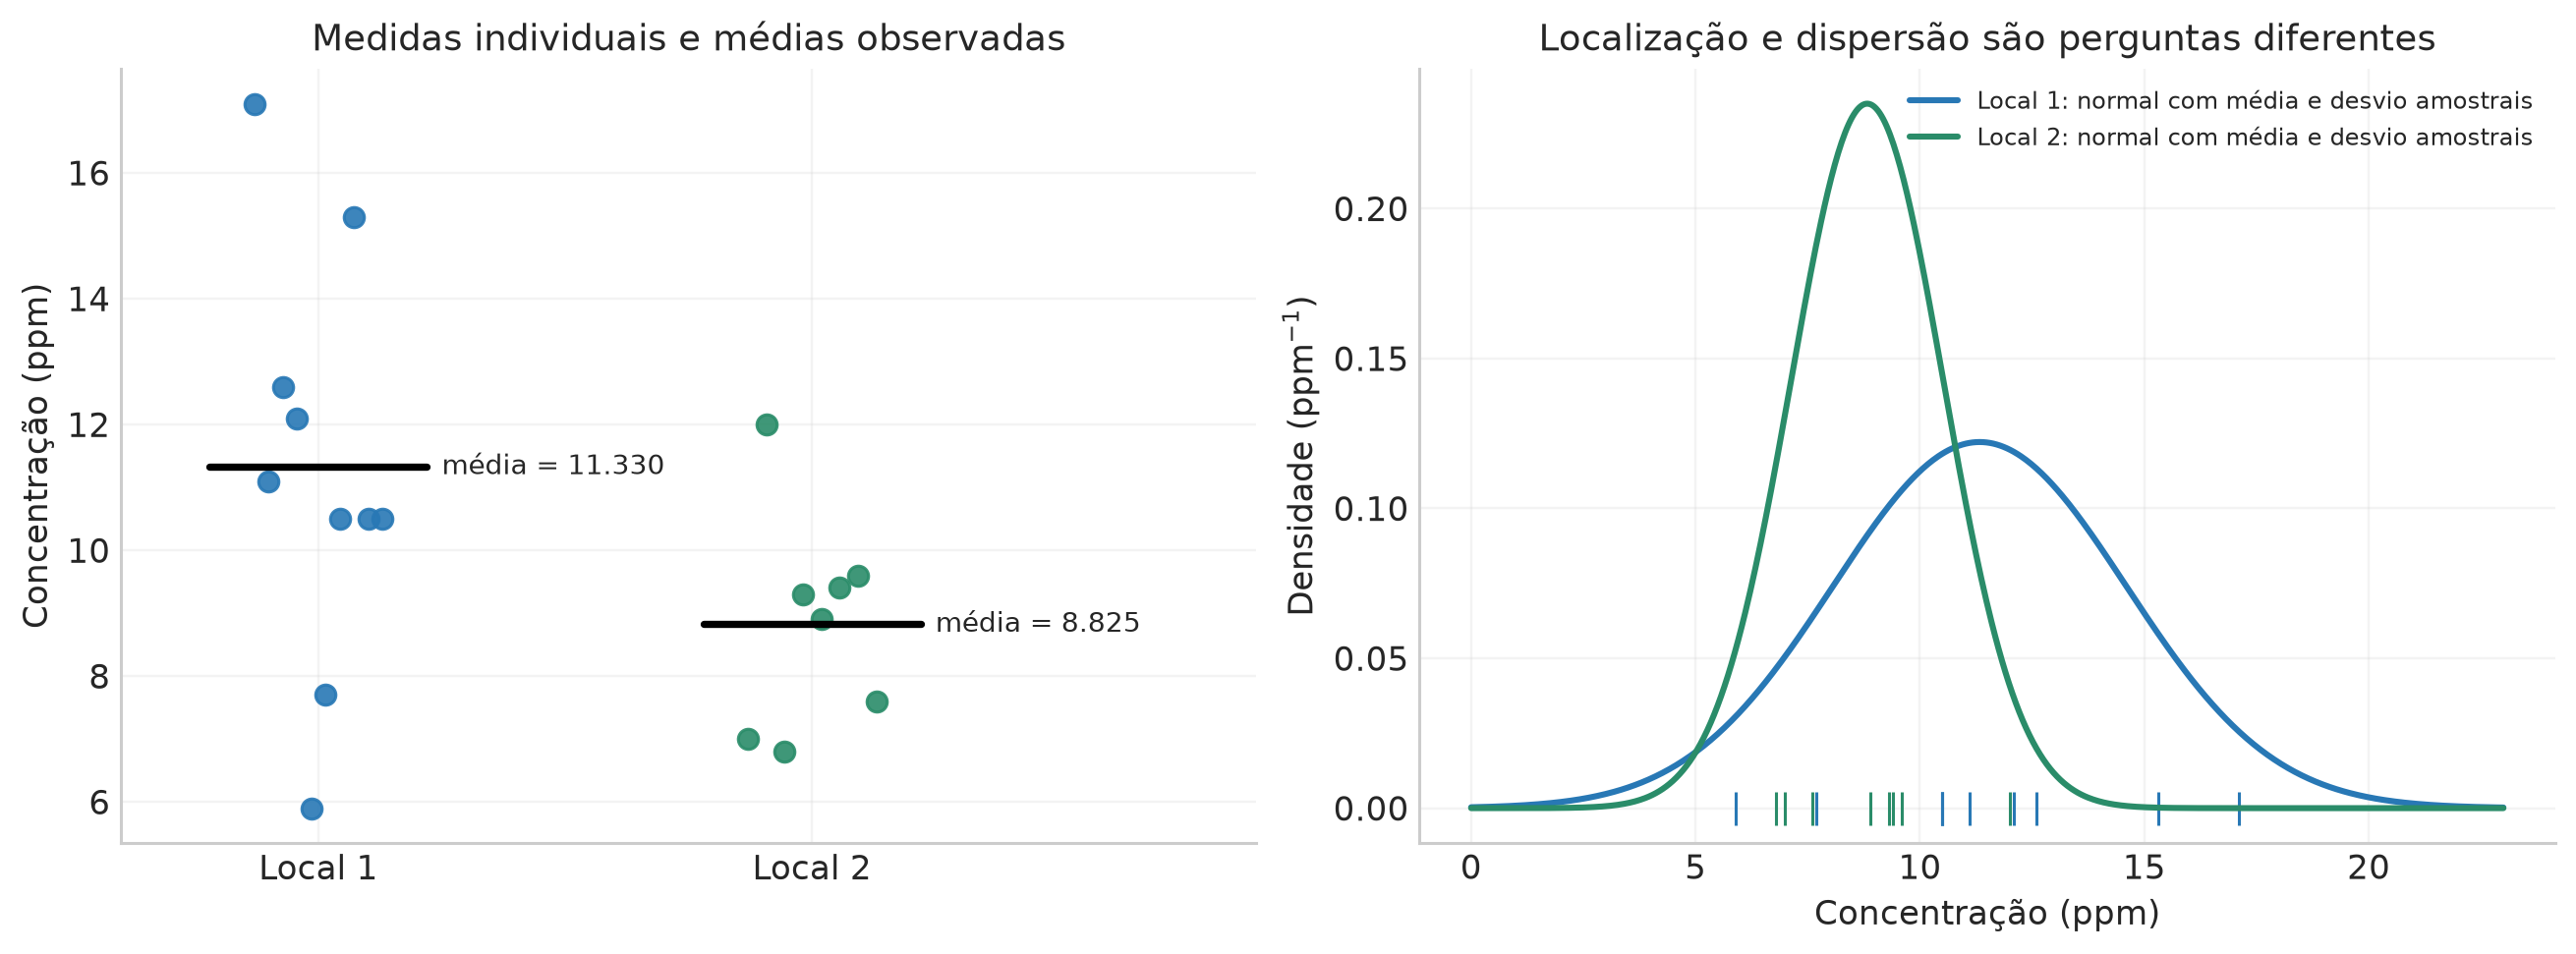

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11.8,4.3), layout="constrained")
for j, (x, cor) in enumerate(zip(q1_grupos, [AZUL, VERDE])):
    # Deslocamento horizontal determinístico para tornar medidas repetidas visíveis.
    ax[0].scatter(j + np.linspace(-.13,.13,len(x)), x, s=45, color=cor, alpha=.9)
    ax[0].plot([j-.22,j+.22], [x.mean(),x.mean()], color="black", lw=2.4)
    ax[0].text(j+.25, x.mean(), f"média = {x.mean():.3f}", va="center", fontsize=9)
z = np.linspace(0,23,600)
for j, cor in enumerate([AZUL,VERDE]):
    ax[1].plot(z, stats.norm.pdf(z,q1_media[j],q1_s[j]), color=cor,
               label=f"Local {j+1}: normal com média e desvio amostrais")
    ax[1].plot(q1_grupos[j], np.zeros(q1_n[j]), "|", color=cor, ms=11)
ax[0].set(xticks=[0,1], xticklabels=["Local 1","Local 2"], xlim=(-.4,1.9),
          ylabel="Concentração (ppm)", title="Medidas individuais e médias observadas")
ax[1].set(xlabel="Concentração (ppm)", ylabel=r"Densidade ($\mathrm{ppm}^{-1}$)",
          title="Localização e dispersão são perguntas diferentes")
ax[1].legend(fontsize=8)
figura(fig,"q1_dados_e_dispersoes")

As curvas da direita são normais com os parâmetros substituídos pelos resumos amostrais. Servem para visualizar a diferença de localização e dispersão; **não são posteriores dos parâmetros nem demonstram a normalidade das populações**. A normalidade foi assumida no enunciado.

## Item (a) · De onde vêm os intervalos de confiança?

### Por que aparecem $n-1$ graus de liberdade e uma $\chi^2$?

Vamos começar com um único grupo, omitindo o índice $j$:

$$X_i\overset{\mathrm{iid}}\sim\mathcal N(\mu,\sigma^2),\qquad
Z_i=\frac{X_i-\mu}{\sigma}\overset{\mathrm{iid}}\sim\mathcal N(0,1).$$

O vetor $\boldsymbol Z$ tem $n$ componentes normais padrão independentes. Podemos fazer uma rotação ortogonal cuja primeira direção seja $(1,\ldots,1)/\sqrt n$. A primeira coordenada rotacionada é

$$Z_0=\frac{\sqrt n(\bar X-\mu)}{\sigma}\sim\mathcal N(0,1).$$

As outras $n-1$ coordenadas são perpendiculares a essa direção e representam os resíduos em relação à média. A rotação preserva a distribuição normal padrão conjunta; por isso suas coordenadas continuam independentes. Além disso, preserva a soma dos quadrados:

$$\sum_{i=1}^{n}\frac{(X_i-\mu)^2}{\sigma^2}
=\frac{n(\bar X-\mu)^2}{\sigma^2}
+\frac{\sum_i(X_i-\bar X)^2}{\sigma^2}.$$

O último termo é a soma dos quadrados das $n-1$ coordenadas restantes. Portanto,

$$\boxed{U=\frac{(n-1)S^2}{\sigma^2}\sim\chi^2_{n-1},
\qquad U\ \text{é independente de }\bar X.}$$

É essa decomposição que explica tanto o $n-1$ quanto a independência usada a seguir. A densidade de $U$, com $\nu=n-1$, é

$$f_{\chi^2_\nu}(u)=\frac{u^{\nu/2-1}e^{-u/2}}{2^{\nu/2}\Gamma(\nu/2)},\quad u>0,
\qquad\Gamma(a)=\int_0^\infty t^{a-1}e^{-t}\,dt.$$

### Para uma média: substituir a escala desconhecida produz uma Student

Se conhecêssemos $\sigma$, usaríamos diretamente $Z_0$. Como estimamos a escala com a própria amostra, construímos

$$T=\frac{Z_0}{\sqrt{U/\nu}}
=\frac{\bar X-\mu}{S/\sqrt n}\sim t_\nu.$$


Podemos ver a origem da densidade de Student pela mudança $z=t\sqrt{u/\nu}$. O jacobiano em $z$ é $\sqrt{u/\nu}$; integrando sobre a escala auxiliar,

$$\begin{aligned}
f_T(t)
&=\int_0^\infty
\frac{e^{-t^2u/(2\nu)}}{\sqrt{2\pi}}
\frac{u^{\nu/2-1}e^{-u/2}}{2^{\nu/2}\Gamma(\nu/2)}
\sqrt{\frac u\nu}\,du\\
&=\frac{\Gamma[(\nu+1)/2]}{\sqrt{\nu\pi}\,\Gamma(\nu/2)}
\left(1+\frac{t^2}{\nu}\right)^{-(\nu+1)/2}.
\end{aligned}$$

A integral é do tipo Gamma, com potência $u^{(\nu+1)/2-1}$ e coeficiente exponencial $(1+t^2/\nu)/2$. A incerteza adicional na escala produz caudas mais largas que as de uma normal padrão.

### Inverter a probabilidade para obter o intervalo da média

Pela simetria da Student, com $t_*=q_{0{,}975}(t_\nu)$,

$$P\left(-t_*\le\frac{\bar X-\mu}{S/\sqrt n}\le t_*\right)=0{,}95.$$

Multiplicando por $S/\sqrt n>0$ e isolando $\mu$,

$$\boxed{I_\mu(D)=\left[\bar X-t_*\frac S{\sqrt n},\ 
\bar X+t_*\frac S{\sqrt n}\right].}$$

### Para a variância: a inversão troca a ordem dos quantis

Da mesma forma,

$$P\left(q_{0{,}025}(\chi^2_\nu)\le
\frac{\nu S^2}{\sigma^2}\le q_{0{,}975}(\chi^2_\nu)\right)=0{,}95.$$

Todos os termos são positivos. Ao tomar os recíprocos, as desigualdades se invertem:

$$\frac1{q_{0{,}975}}\le\frac{\sigma^2}{\nu S^2}
\le\frac1{q_{0{,}025}}.$$

Logo,

$$\boxed{I_{\sigma^2}(D)=\left[
\frac{\nu S^2}{q_{0{,}975}(\chi^2_\nu)},\ 
\frac{\nu S^2}{q_{0{,}025}(\chi^2_\nu)}\right].}$$

O intervalo é assimétrico. A distribuição de referência descreve a soma de quadrados, e o parâmetro desejado aparece no denominador dessa estatística.

In [4]:
q1_tcrit = stats.t.ppf(1-q1_alpha/2, q1_nu)
q1_chi_lo = stats.chi2.ppf(q1_alpha/2, q1_nu)
q1_chi_hi = stats.chi2.ppf(1-q1_alpha/2, q1_nu)
q1_ci_media = np.column_stack((q1_media-q1_tcrit*q1_se, q1_media+q1_tcrit*q1_se))
q1_ci_var = np.column_stack((q1_Q/q1_chi_hi, q1_Q/q1_chi_lo))
tabela("q1_a_quantis", ["Local", "nu", "t(97,5%)", "chi²(2,5%)", "chi²(97,5%)"],
       [[j+1,int(q1_nu[j]),q1_tcrit[j],q1_chi_lo[j],q1_chi_hi[j]] for j in range(2)],casas=7)
tabela("q1_a_intervalos", ["Local", "Média inferior (ppm)", "Média superior (ppm)",
                           "Variância inferior (ppm²)", "Variância superior (ppm²)"],
       [[j+1,*q1_ci_media[j],*q1_ci_var[j]] for j in range(2)],casas=6)

for j in range(2):
    display(Markdown(
        f"**Local {j+1}:** média: ${q1_media[j]:.3f} \\pm "
        f"{q1_tcrit[j]:.6f}\\,{q1_s[j]:.6f}/\\sqrt{{{q1_n[j]}}}$ ppm; "
        f"variância: $[{q1_Q[j]:.3f}/{q1_chi_hi[j]:.6f}, "
        f"{q1_Q[j]:.3f}/{q1_chi_lo[j]:.6f}]$ ppm²."
    ))
    conferir(f"IC da média do local {j+1}: inversão coincide com t.interval",
             np.allclose(q1_ci_media[j], stats.t.interval(.95,q1_nu[j],loc=q1_media[j],scale=q1_se[j])))
    conferir(f"IC da variância do local {j+1}: caudas de 2,5% e 97,5%",
             np.allclose(stats.chi2.cdf(q1_Q[j]/q1_ci_var[j],q1_nu[j]),[.975,.025]))

| Local | nu | t(97,5%) | chi²(2,5%) | chi²(97,5%) |
| :-- | :-- | :-- | :-- | :-- |
| 1 | 9 | 2,2621572 | 2,7003895 | 19,0227678 |
| 2 | 7 | 2,3646243 | 1,6898692 | 16,0127643 |

| Local | Média inferior (ppm) | Média superior (ppm) | Variância inferior (ppm²) | Variância superior (ppm²) |
| :-- | :-- | :-- | :-- | :-- |
| 1 | 8,993155 | 13,666845 | 5,048740 | 35,565610 |
| 2 | 7,405698 | 10,244302 | 1,259932 | 11,938794 |

**Local 1:** média: $11.330 \pm 2.262157\,3.266684/\sqrt{10}$ ppm; variância: $[96.041/19.022768, 96.041/2.700389]$ ppm².

**Local 2:** média: $8.825 \pm 2.364624\,1.697688/\sqrt{8}$ ppm; variância: $[20.175/16.012764, 20.175/1.689869]$ ppm².

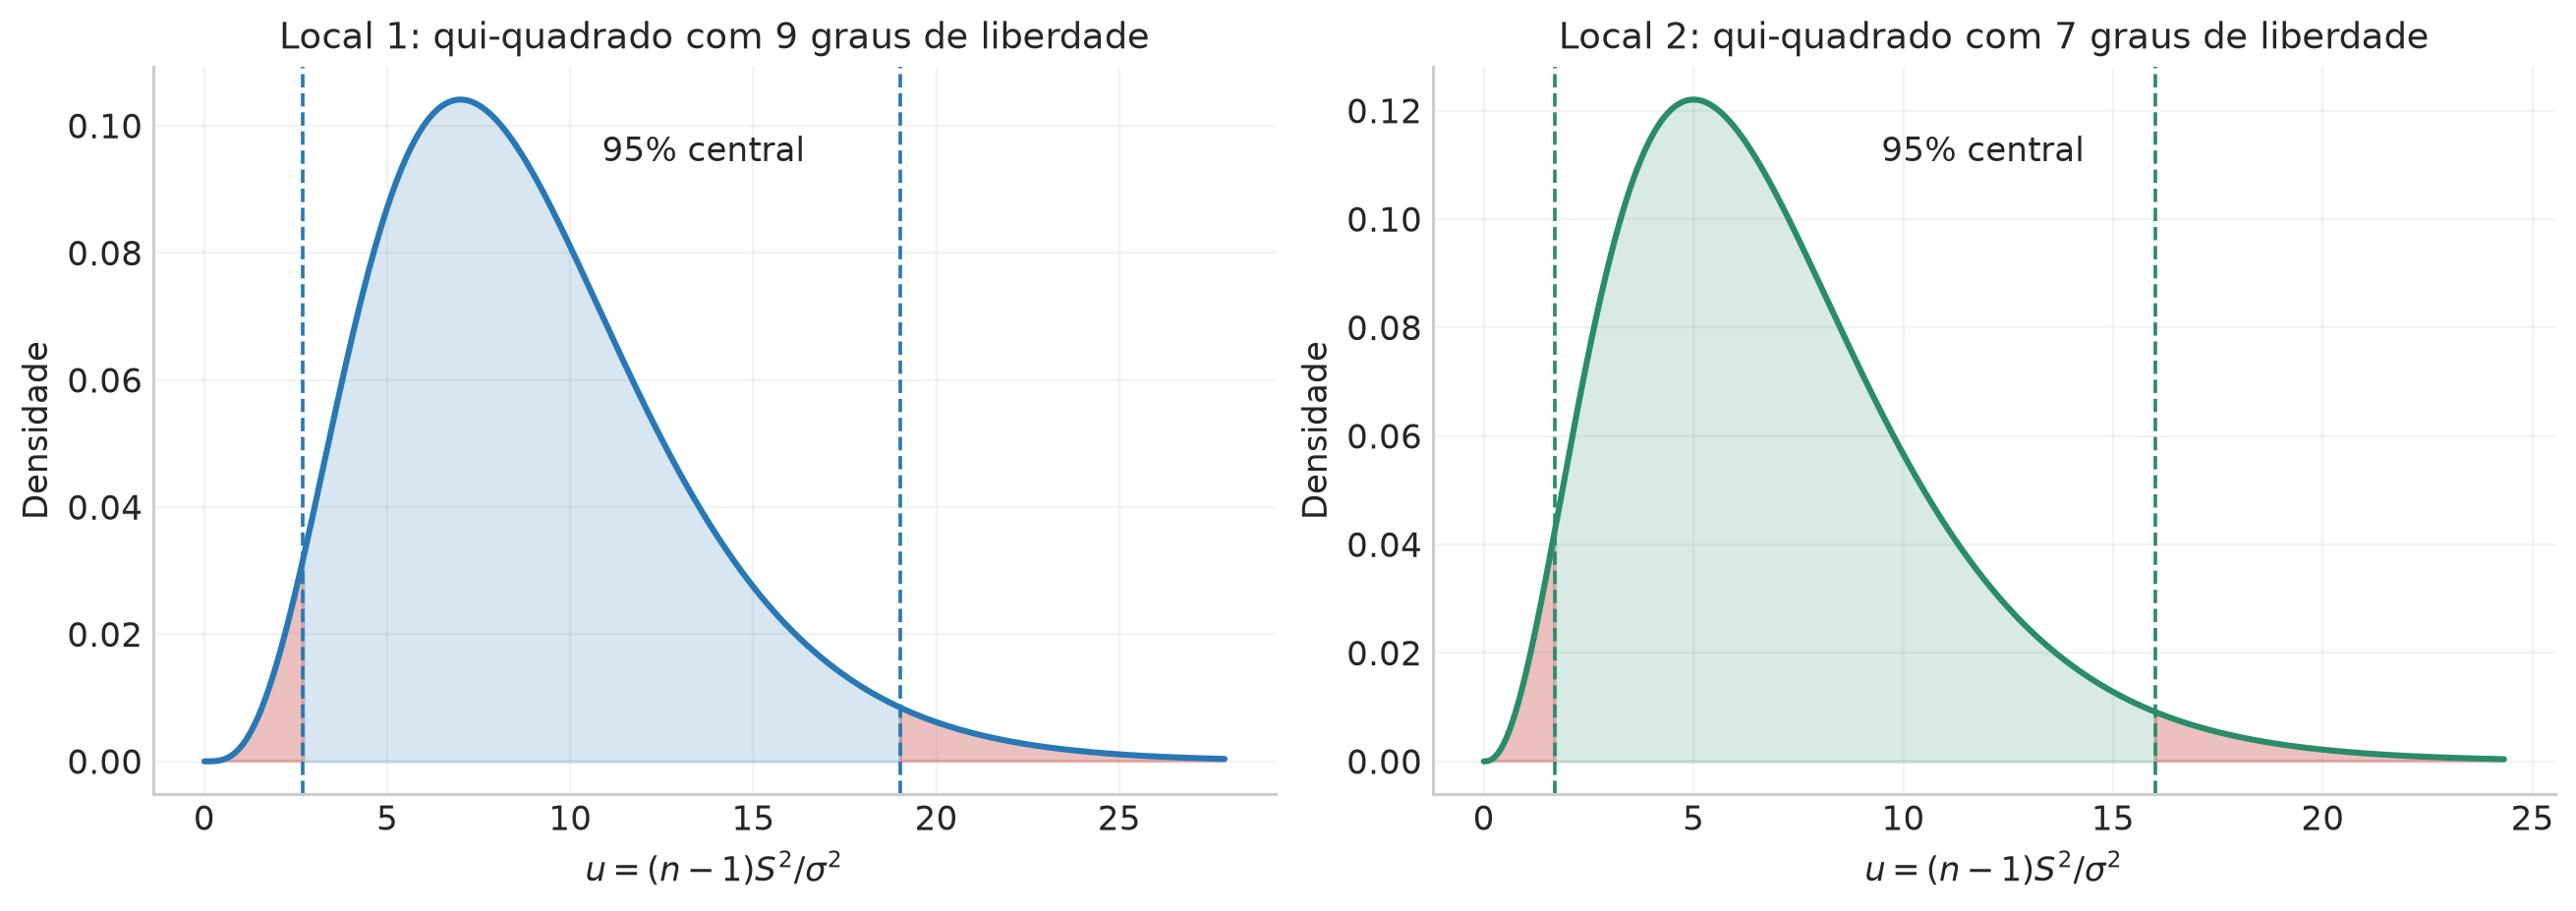

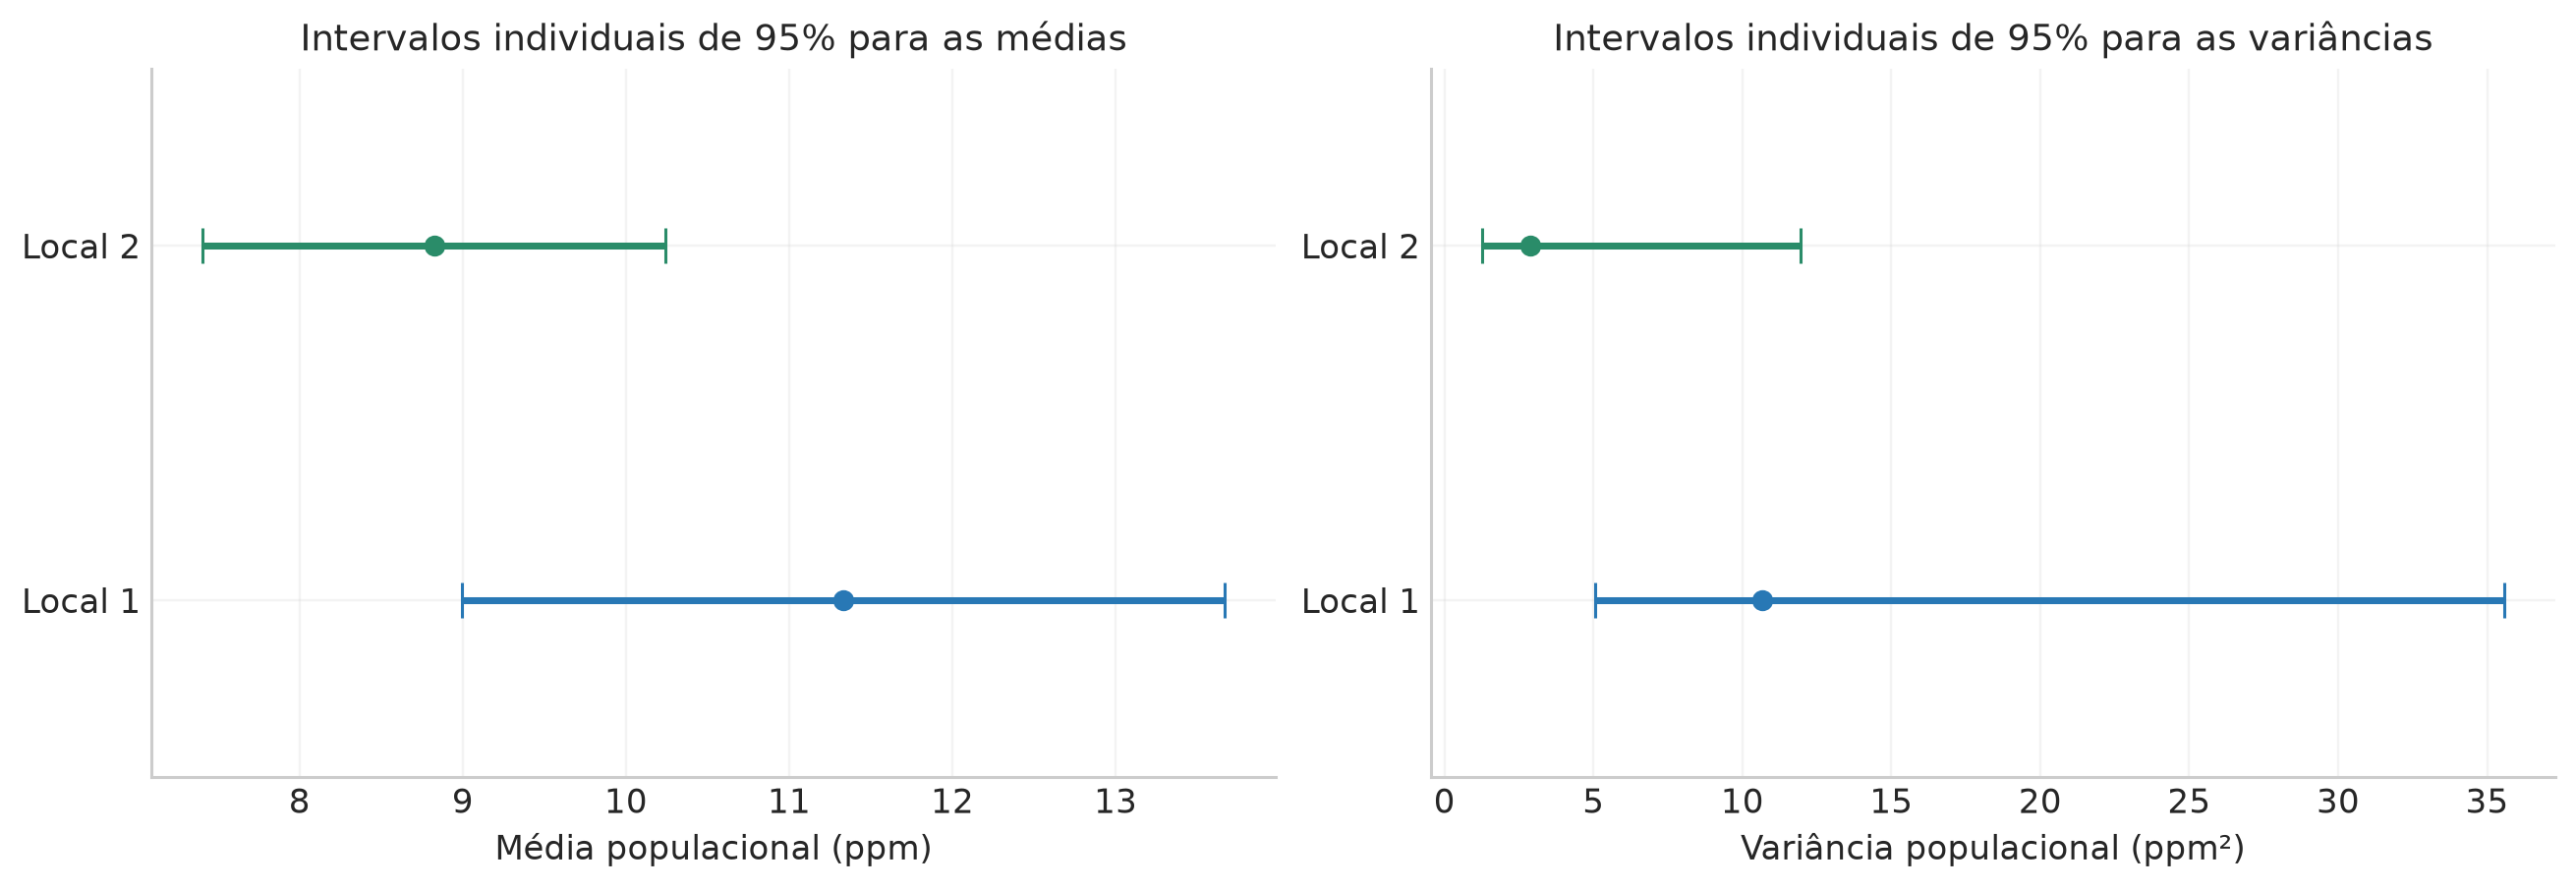

In [5]:
fig, ax = plt.subplots(1,2,figsize=(11.8,4.1),layout="constrained")
for j,(cor,nu) in enumerate(zip([AZUL,VERDE],q1_nu)):
    u=np.linspace(0,stats.chi2.ppf(.999,nu),1500)
    pdf=stats.chi2.pdf(u,nu)
    ax[j].plot(u,pdf,color=cor)
    ax[j].fill_between(u,pdf,where=(u>=q1_chi_lo[j])&(u<=q1_chi_hi[j]),color=cor,alpha=.18)
    ax[j].fill_between(u,pdf,where=(u<=q1_chi_lo[j])|(u>=q1_chi_hi[j]),color=VERMELHO,alpha=.35)
    for v in [q1_chi_lo[j],q1_chi_hi[j]]:ax[j].axvline(v,color=cor,ls="--",lw=1.2)
    ax[j].text(.49,.87,"95% central",transform=ax[j].transAxes,ha="center")
    ax[j].set(xlabel=r"$u=(n-1)S^2/\sigma^2$",ylabel="Densidade",
              title=f"Local {j+1}: qui-quadrado com {nu} graus de liberdade")
figura(fig,"q1_a_quiquadrado_e_quantis")

fig,ax=plt.subplots(1,2,figsize=(11.8,4),layout="constrained")
for j,cor in enumerate([AZUL,VERDE]):
    ax[0].errorbar(q1_media[j],j,xerr=np.array([[q1_media[j]-q1_ci_media[j,0]],
                    [q1_ci_media[j,1]-q1_media[j]]]),fmt="o",color=cor,capsize=6,lw=2.3)
    ax[1].errorbar(q1_var[j],j,xerr=np.array([[q1_var[j]-q1_ci_var[j,0]],
                    [q1_ci_var[j,1]-q1_var[j]]]),fmt="o",color=cor,capsize=6,lw=2.3)
for a in ax:a.set(yticks=[0,1],yticklabels=["Local 1","Local 2"],ylim=(-.5,1.5))
ax[0].set(xlabel="Média populacional (ppm)",title="Intervalos individuais de 95% para as médias")
ax[1].set(xlabel="Variância populacional (ppm²)",title="Intervalos individuais de 95% para as variâncias")
figura(fig,"q1_a_intervalos_individuais")

### Interpretando os intervalos

Os resultados são

$$\begin{array}{c|cc}
&\text{média (ppm)}&\text{variância (ppm²)}\\\hline
\text{Local 1}&[8{,}993155;\ 13{,}666845]&[5{,}048740;\ 35{,}565610]\\
\text{Local 2}&[7{,}405698;\ 10{,}244302]&[1{,}259932;\ 11{,}938794].
\end{array}$$

A incerteza na variância do local 1 é grande, mesmo tendo mais medidas. Isso acontece porque a dispersão amostral também é maior. O erro da média depende de ambos: $s/\sqrt n$.

**O que significa o 95%?** Se repetíssemos as coletas e reconstruíssemos o intervalo pela mesma regra, 95% dos intervalos de cada tipo cobririam seu parâmetro verdadeiro. Nesta abordagem, o parâmetro é fixo e o intervalo é aleatório. Não calculamos aqui uma probabilidade posterior de 95% para o parâmetro. 

Os intervalos individuais se sobrepõem, mas essa sobreposição não é nossa regra de teste para igualdade de médias ou variâncias. Precisamos construir diretamente a estatística da **diferença** ou da **razão**.

### Onde o gráfico de $\chi^2$ ajuda — e qual pergunta ele responde?

O gráfico anterior mostra os quantis usados para inverter o pivô da variância. Ele ajuda a construir os limites de confiança. Para testar igualdade de **duas** variâncias desconhecidas, entretanto, precisamos eliminar a escala comum; isso será feito pela razão $F$.

Usar $Q_j/s_j^2$ como suposto teste de ajuste seria circular: pela própria definição, $Q_j/s_j^2=n_j-1$. Sem uma escala especificada independentemente, esse número não fornece um diagnóstico de consistência. Por isso vamos usar $\chi^2$, $F$ e Student nas perguntas para as quais foram construídos.

## Item (b) · As variâncias populacionais são iguais?

Definimos

$$H_{0,\sigma}:\sigma_1^2=\sigma_2^2,
\qquad H_{1,\sigma}:\sigma_1^2\ne\sigma_2^2.$$

A alternativa admite tanto $\sigma_1^2>\sigma_2^2$ quanto o contrário. Portanto, o teste é **bilateral**. Observar $s_1^2>s_2^2$ depois da coleta não modifica essa escolha.

### Da razão de qui-quadrados à distribuição $F$

Já mostramos que

$$U_1=\frac{\nu_1 S_1^2}{\sigma_1^2}\sim\chi^2_{\nu_1},
\qquad U_2=\frac{\nu_2 S_2^2}{\sigma_2^2}\sim\chi^2_{\nu_2}.$$

Como as amostras são independentes, $U_1$ e $U_2$ também são. Sua razão padronizada é

$$F=\frac{U_1/\nu_1}{U_2/\nu_2}
=\frac{S_1^2/S_2^2}{\sigma_1^2/\sigma_2^2}\sim F_{\nu_1,\nu_2}.$$

Sob $H_{0,\sigma}$, a razão populacional vale 1 e obtemos a estatística observável

$$\boxed{F_{\rm obs}=\frac{s_1^2}{s_2^2}\quad\text{comparada com }F_{9,7}.}$$

Mantemos o local 1 no numerador desde o início; não reordenamos as amostras para produzir uma cauda desejada.

Para abrir também a densidade usada no cálculo: se $v=U_2$, então $U_1=(\nu_1/\nu_2)fv$ e o jacobiano da mudança $(U_1,U_2)\to(f,v)$ é $(\nu_1/\nu_2)v$. Assim,

$$\begin{aligned}
f_F(f)&=\int_0^\infty f_{\chi^2_{\nu_1}}\!\left(\frac{\nu_1}{\nu_2}fv\right)
f_{\chi^2_{\nu_2}}(v)\frac{\nu_1}{\nu_2}v\,dv\\
&=\frac{\Gamma[(\nu_1+\nu_2)/2]}{\Gamma(\nu_1/2)\Gamma(\nu_2/2)}
\left(\frac{\nu_1}{\nu_2}\right)^{\nu_1/2}
\frac{f^{\nu_1/2-1}}{[1+(\nu_1/\nu_2)f]^{(\nu_1+\nu_2)/2}},\qquad f>0.
\end{aligned}$$

A segunda linha resulta da integral Gamma em $v$, agora com potência $(\nu_1+\nu_2)/2-1$.

### Definir o valor-p de um teste bilateral assimétrico

A distribuição $F$ é assimétrica. Vamos usar o teste bilateral de **caudas iguais**, que reserva $\alpha/2$ para cada direção. Se $G_F$ é a CDF de $F_{9,7}$,

$$\boxed{p_F=\min\{1,\ 2\min[G_F(F_{\rm obs}),\ 1-G_F(F_{\rm obs})]\}.}$$

Essa definição especifica o que estamos chamando de bilateral; não somamos pontos a uma mesma distância geométrica de 1. Para $\alpha=0{,}05$, a região crítica equivalente é

$$F_{\rm obs}<q_{0{,}025}(F_{9,7})
\quad\text{ou}\quad
F_{\rm obs}>q_{0{,}975}(F_{9,7}).$$

Uma escolha diferente de ordenação para um teste bilateral poderia definir outro valor-p. Aqui a convenção é explicitamente a mesma usada nos intervalos de caudas iguais.

In [6]:
q1_Fobs = q1_var[0]/q1_var[1]
q1_Fdist = stats.f(q1_nu[0],q1_nu[1])
q1_Fcdf = q1_Fdist.cdf(q1_Fobs)
q1_Fsf = q1_Fdist.sf(q1_Fobs)  # sf calcula a cauda superior sem subtrair de 1.
q1_pF = min(1.,2*min(q1_Fcdf,q1_Fsf))
q1_Fcrit = q1_Fdist.ppf([q1_alpha/2,1-q1_alpha/2])
q1_ci_rho = q1_Fobs/q1_Fcrit[::-1]

tabela("q1_b_variancias", ["F observado", "nu1", "nu2", "Cauda inferior", "Cauda superior",
                          "p bilateral", "100(1-p) (%)", "Decisão a 5%"],
       [[q1_Fobs,9,7,q1_Fcdf,q1_Fsf,q1_pF,100*(1-q1_pF),decisao(q1_pF)]],casas=8)
tabela("q1_b_regiao_critica", ["F inferior (2,5%)", "F superior (97,5%)",
                            "IC 95% razão: inferior", "IC 95% razão: superior"],
       [[*q1_Fcrit,*q1_ci_rho]],casas=7)

q1_pF_quad = 2*integrate.quad(q1_Fdist.pdf,q1_Fobs,np.inf,epsabs=1e-11)[0]
conferir("p F: integração explícita coincide com a função de sobrevivência",
         np.isclose(q1_pF,q1_pF_quad,rtol=1e-9))
conferir("F: decisão por p coincide com decisão pelos quantis",
         (q1_pF<q1_alpha)==((q1_Fobs<q1_Fcrit[0]) or (q1_Fobs>q1_Fcrit[1])))
conferir("F: inverter a ordem das amostras preserva p bilateral",
         np.isclose(q1_pF,2*min(stats.f.cdf(1/q1_Fobs,7,9),stats.f.sf(1/q1_Fobs,7,9))))
conferir("F: não rejeição coincide com IC da razão contendo 1", q1_ci_rho[0]<1<q1_ci_rho[1])

| F observado | nu1 | nu2 | Cauda inferior | Cauda superior | p bilateral | 100(1-p) (%) | Decisão a 5% |
| :-- | :-- | :-- | :-- | :-- | :-- | :-- | :-- |
| 3,70253063 | 9 | 7 | 0,95085071 | 0,04914929 | 0,09829859 | 90,17014144 | Não rejeitar H0 |

| F inferior (2,5%) | F superior (97,5%) | IC 95% razão: inferior | IC 95% razão: superior |
| :-- | :-- | :-- | :-- |
| 0,2382628 | 4,8232171 | 0,7676475 | 15,5396937 |

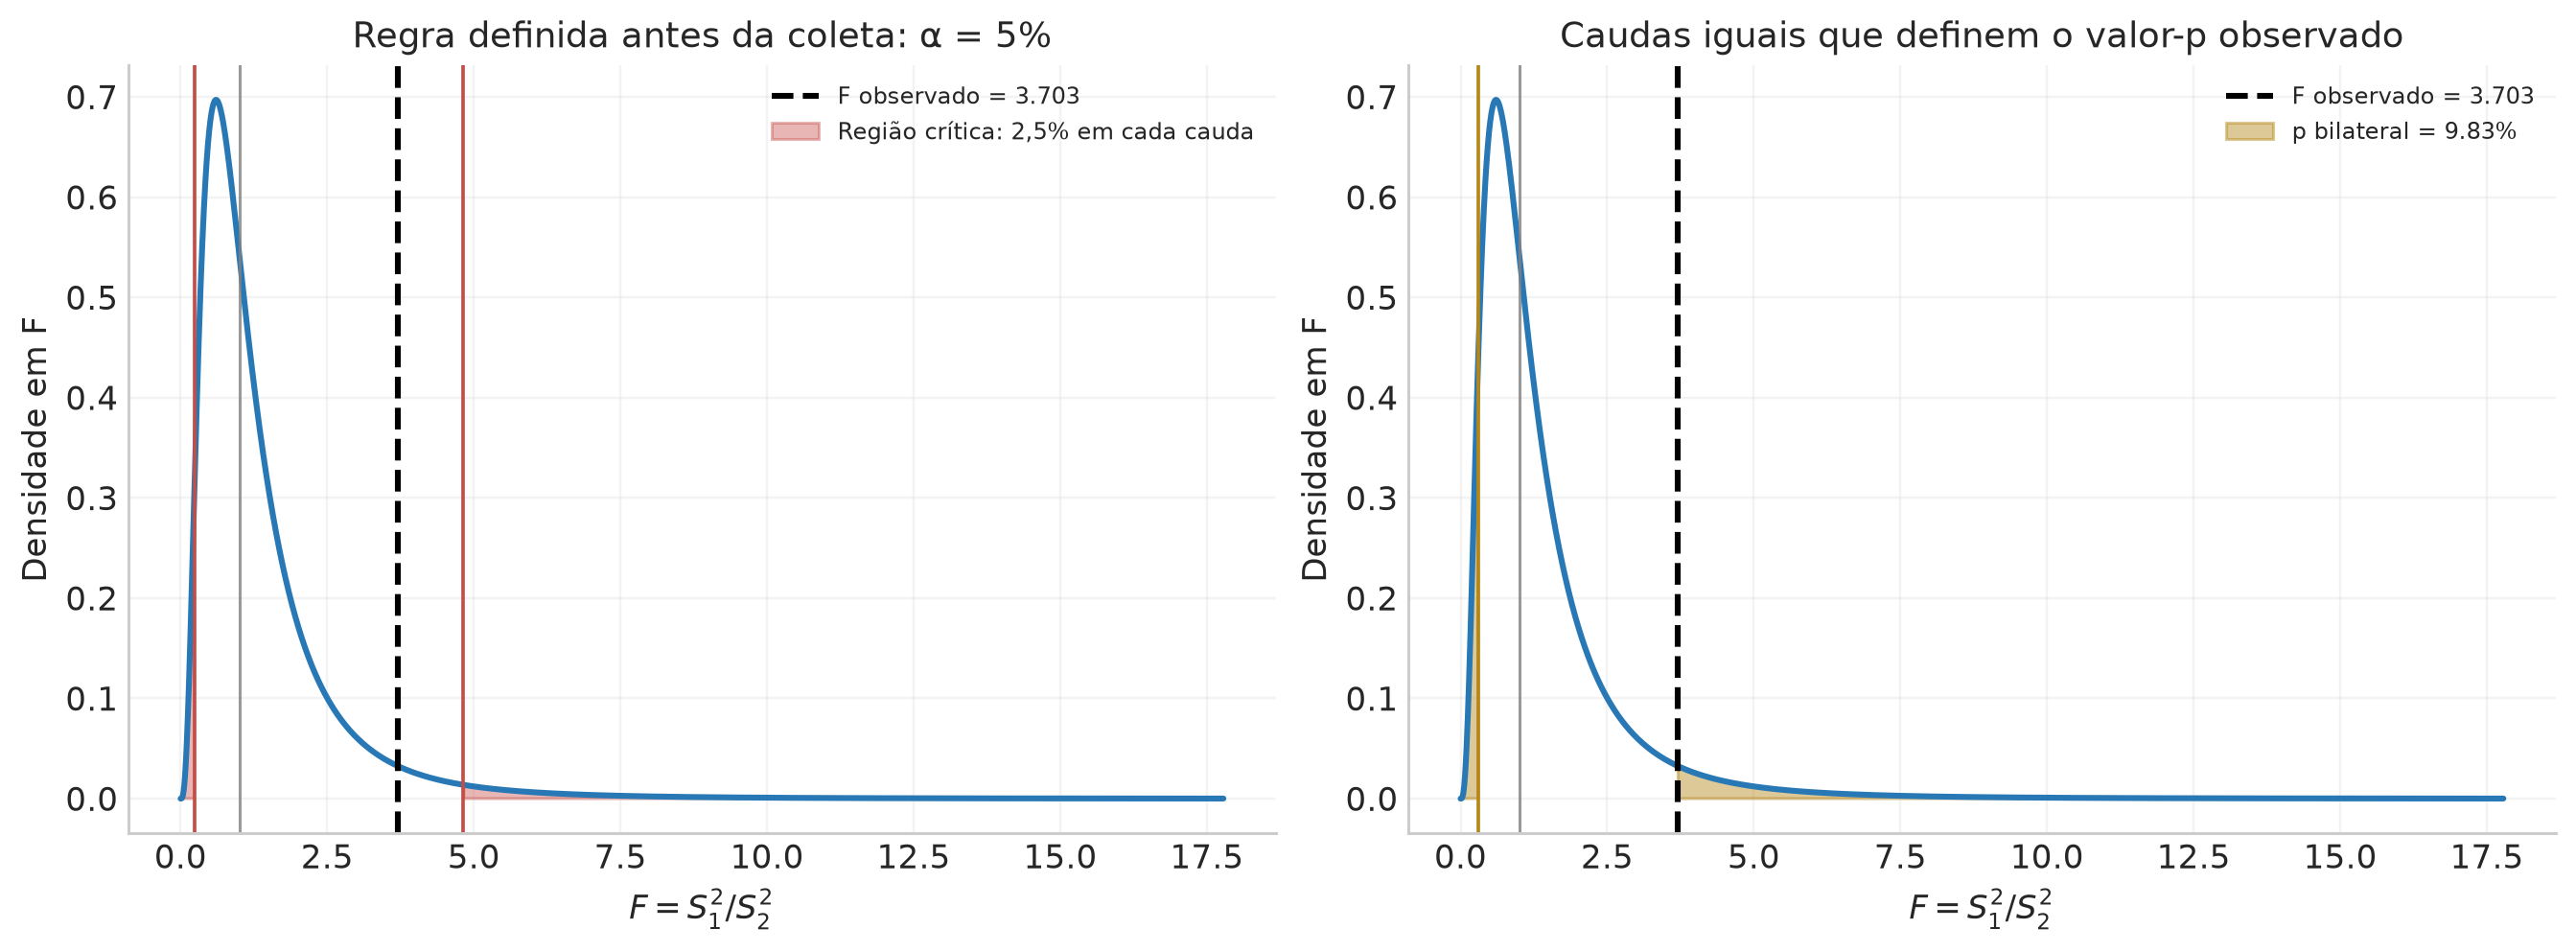

In [7]:
fgrid=np.linspace(0,q1_Fdist.ppf(.9995),2600)
fpdf=q1_Fdist.pdf(fgrid)
q1_Foutro = q1_Fdist.ppf(min(q1_Fcdf,q1_Fsf))
fig,ax=plt.subplots(1,2,figsize=(12.1,4.4),layout="constrained")
for a in ax:
    a.plot(fgrid,fpdf,color=AZUL)
    a.axvline(q1_Fobs,color="black",ls="--",label=f"F observado = {q1_Fobs:.3f}")
    a.set(xlabel=r"$F=S_1^2/S_2^2$",ylabel="Densidade em F")
    a.axvline(1,color="gray",lw=1,alpha=.8)
ax[0].fill_between(fgrid,fpdf,where=(fgrid<=q1_Fcrit[0])|(fgrid>=q1_Fcrit[1]),
                   color=VERMELHO,alpha=.4,label="Região crítica: 2,5% em cada cauda")
for q in q1_Fcrit:ax[0].axvline(q,color=VERMELHO,lw=1.2)
ax[0].set_title("Regra definida antes da coleta: α = 5%")
ax[1].fill_between(fgrid,fpdf,where=(fgrid<=q1_Foutro)|(fgrid>=q1_Fobs),
                   color=OURO,alpha=.45,label=f"p bilateral = {100*q1_pF:.2f}%")
ax[1].axvline(q1_Foutro,color=OURO,lw=1.2)
ax[1].set_title("Caudas iguais que definem o valor-p observado")
for a in ax:a.legend(fontsize=8,loc="upper right")
figura(fig,"q1_b_teste_f_bilateral")

### Resultado e critério de rejeição

Substituindo as variâncias,

$$F_{\rm obs}=\frac{96{,}041/9}{20{,}175/7}=3{,}7025306\ldots.$$

As probabilidades de cauda são

$$G_F(F_{\rm obs})=0{,}9508507\ldots,\qquad
P(F\ge F_{\rm obs}\mid H_{0,\sigma})=0{,}0491493\ldots,$$

e, pela convenção bilateral,

$$\boxed{p_F=2\times0{,}0491493\ldots=0{,}0982986\ldots.}$$

A região crítica a 5% fica abaixo de $0{,}2382628\ldots$ ou acima de $4{,}8232171\ldots$. O resultado observado está entre esses limites. Portanto, **não rejeitamos igualdade das variâncias a 5%**.

Note a importância das caudas: usar apenas $0{,}0491493$ levaria a uma rejeição a 5%, mas responderia a uma pergunta direcional escolhida depois de olhar a amostra. Nossa pergunta original inclui as duas direções, e o valor-p apropriado para a regra estabelecida é aproximadamente $9{,}83\%$.

O intervalo de 95% para a razão também pode ser obtido do pivô $F=(S_1^2/S_2^2)/\rho$:

$$\boxed{\rho\in\left[\frac{F_{\rm obs}}{q_{0{,}975}},
\frac{F_{\rm obs}}{q_{0{,}025}}\right]
=[0{,}767648;\ 15{,}539694].}$$

Esse intervalo contém 1 e é muito largo. Os dados admitem uma faixa extensa de razões populacionais.

### O que o enunciado chama de “nível de confiança para rejeitar”?

Vamos reportar também $C_*=100(1-p)\%$, conforme a linguagem do exercício. Como a rejeição ocorre para $p<\alpha$, o resultado seria rejeitado para níveis de confiança $1-\alpha$ abaixo de $1-p$; $1-p$ é a fronteira dessa regra.

Para as variâncias, $C_*=90{,}17014\ldots\%$. Isso **não é** $P(\sigma_1^2\ne\sigma_2^2\mid D)$ e não significa que haja 90,17% de probabilidade de as variâncias diferirem. É outra maneira de expressar o limiar do mesmo teste frequentista.

## Item (c) · Comparar as médias assumindo variância comum

Agora as hipóteses são

$$H_{0,\mu}:\mu_1=\mu_2,
\qquad H_{1,\mu}:\mu_1\ne\mu_2.$$

**Em ambas as hipóteses deste item**, assumimos $\sigma_1^2=\sigma_2^2=\sigma^2$, desconhecida. A alternativa modifica as médias; a restrição sobre as variâncias pertence ao modelo de observação. O teste é bilateral porque tanto uma diferença positiva quanto uma negativa contradizem $H_{0,\mu}$.

### Construir a escala da diferença

A independência das amostras dá

$$\bar X_1-\bar X_2\sim
\mathcal N\left(\delta,\ \sigma^2\left[\frac1{n_1}+\frac1{n_2}\right]\right).$$

Precisamos estimar uma única $\sigma^2$. Cada grupo fornece uma soma de quadrados independente:

$$\frac{\mathcal Q_1}{\sigma^2}\sim\chi^2_{\nu_1},\qquad
\frac{\mathcal Q_2}{\sigma^2}\sim\chi^2_{\nu_2}.$$

A soma de qui-quadrados independentes é uma qui-quadrado com graus de liberdade somados. Isso também pode ser visto pela função geradora, $(1-2t)^{-\nu_1/2}(1-2t)^{-\nu_2/2}=(1-2t)^{-(\nu_1+\nu_2)/2}$. Portanto,

$$\frac{\mathcal Q_1+\mathcal Q_2}{\sigma^2}\sim\chi^2_{\nu_1+\nu_2}.$$

Definimos a variância combinada (*pooled*)

$$\boxed{S_p^2=\frac{\mathcal Q_1+\mathcal Q_2}{n_1+n_2-2}
=\frac{(n_1-1)S_1^2+(n_2-1)S_2^2}{n_1+n_2-2}.}$$

Ela é uma média das variâncias ponderada por seus graus de liberdade, não uma média simples. Além disso,

$$\mathbb E[S_p^2]=\frac{\nu_1\sigma^2+\nu_2\sigma^2}{\nu_1+\nu_2}=\sigma^2.$$

A diferença das médias é independente dos resíduos dos dois grupos. Podemos, assim, formar a razão entre uma normal padrão e a raiz de uma qui-quadrado padronizada:

$$\boxed{T_p=\frac{(\bar X_1-\bar X_2)-\delta_0}
{S_p\sqrt{1/n_1+1/n_2}}\sim t_{n_1+n_2-2}\quad\text{sob }\delta=\delta_0.}$$

Para igualdade de médias, $\delta_0=0$. Como Student é simétrica,

$$p_p=P(|T_p|\ge|t_{p,\rm obs}|\mid H_{0,\mu})
=2\int_{|t_{p,\rm obs}|}^{\infty}f_{t_{16}}(t)\,dt.$$

A região crítica a 5% é $|t_{p,\rm obs}|>q_{0{,}975}(t_{16})$. A inversão do mesmo pivô fornece o intervalo de confiança para a diferença:

$$I_{\delta,p}=\left[(\bar x_1-\bar x_2)\pm
q_{0{,}975}(t_{16})s_p\sqrt{1/n_1+1/n_2}\right].$$

Aqui $[a\pm b]$ abrevia $[a-b,a+b]$.

In [8]:
q1_nup = int(q1_nu.sum())
q1_sp2 = q1_Q.sum()/q1_nup
q1_sep = np.sqrt(q1_sp2*np.sum(1/q1_n))
q1_tp = q1_delta_obs/q1_sep
q1_pp = 2*stats.t.sf(abs(q1_tp),q1_nup)
q1_tcp = stats.t.ppf(1-q1_alpha/2,q1_nup)
q1_cip = q1_delta_obs + np.array([-1,1])*q1_tcp*q1_sep

tabela("q1_c_media_variancia_comum", ["s_p² (ppm²)","SE da diferença (ppm)","t observado", "nu", "t crítico",
                                    "p bilateral", "100(1-p) (%)", "Decisão a 5%"],
       [[q1_sp2,q1_sep,q1_tp,q1_nup,q1_tcp,q1_pp,100*(1-q1_pp),decisao(q1_pp)]],casas=8)
tabela("q1_c_intervalo_diferenca",["Diferença (ppm)","IC 95% inferior (ppm)","IC 95% superior (ppm)"],
       [[q1_delta_obs,*q1_cip]],casas=7)
q1_scipy_p = stats.ttest_ind(q1_x1,q1_x2,equal_var=True,alternative="two-sided")
conferir("Student pooled: estatística e p coincidem com SciPy",
         np.allclose([q1_tp,q1_pp],[q1_scipy_p.statistic,q1_scipy_p.pvalue]))
conferir("Student pooled: integral explícita da cauda",
         np.isclose(q1_pp,2*integrate.quad(lambda t:stats.t.pdf(t,q1_nup),abs(q1_tp),np.inf)[0]))
conferir("Student pooled: IC da diferença coincide com SciPy",
         np.allclose(q1_cip,q1_scipy_p.confidence_interval(confidence_level=.95)))

| s_p² (ppm²) | SE da diferença (ppm) | t observado | nu | t crítico | p bilateral | 100(1-p) (%) | Decisão a 5% |
| :-- | :-- | :-- | :-- | :-- | :-- | :-- | :-- |
| 7,26350000 | 1,27839255 | 1,95949203 | 16 | 2,11990530 | 0,06771440 | 93,22855980 | Não rejeitar H0 |

| Diferença (ppm) | IC 95% inferior (ppm) | IC 95% superior (ppm) |
| :-- | :-- | :-- |
| 2,5050000 | -0,2050711 | 5,2150711 |

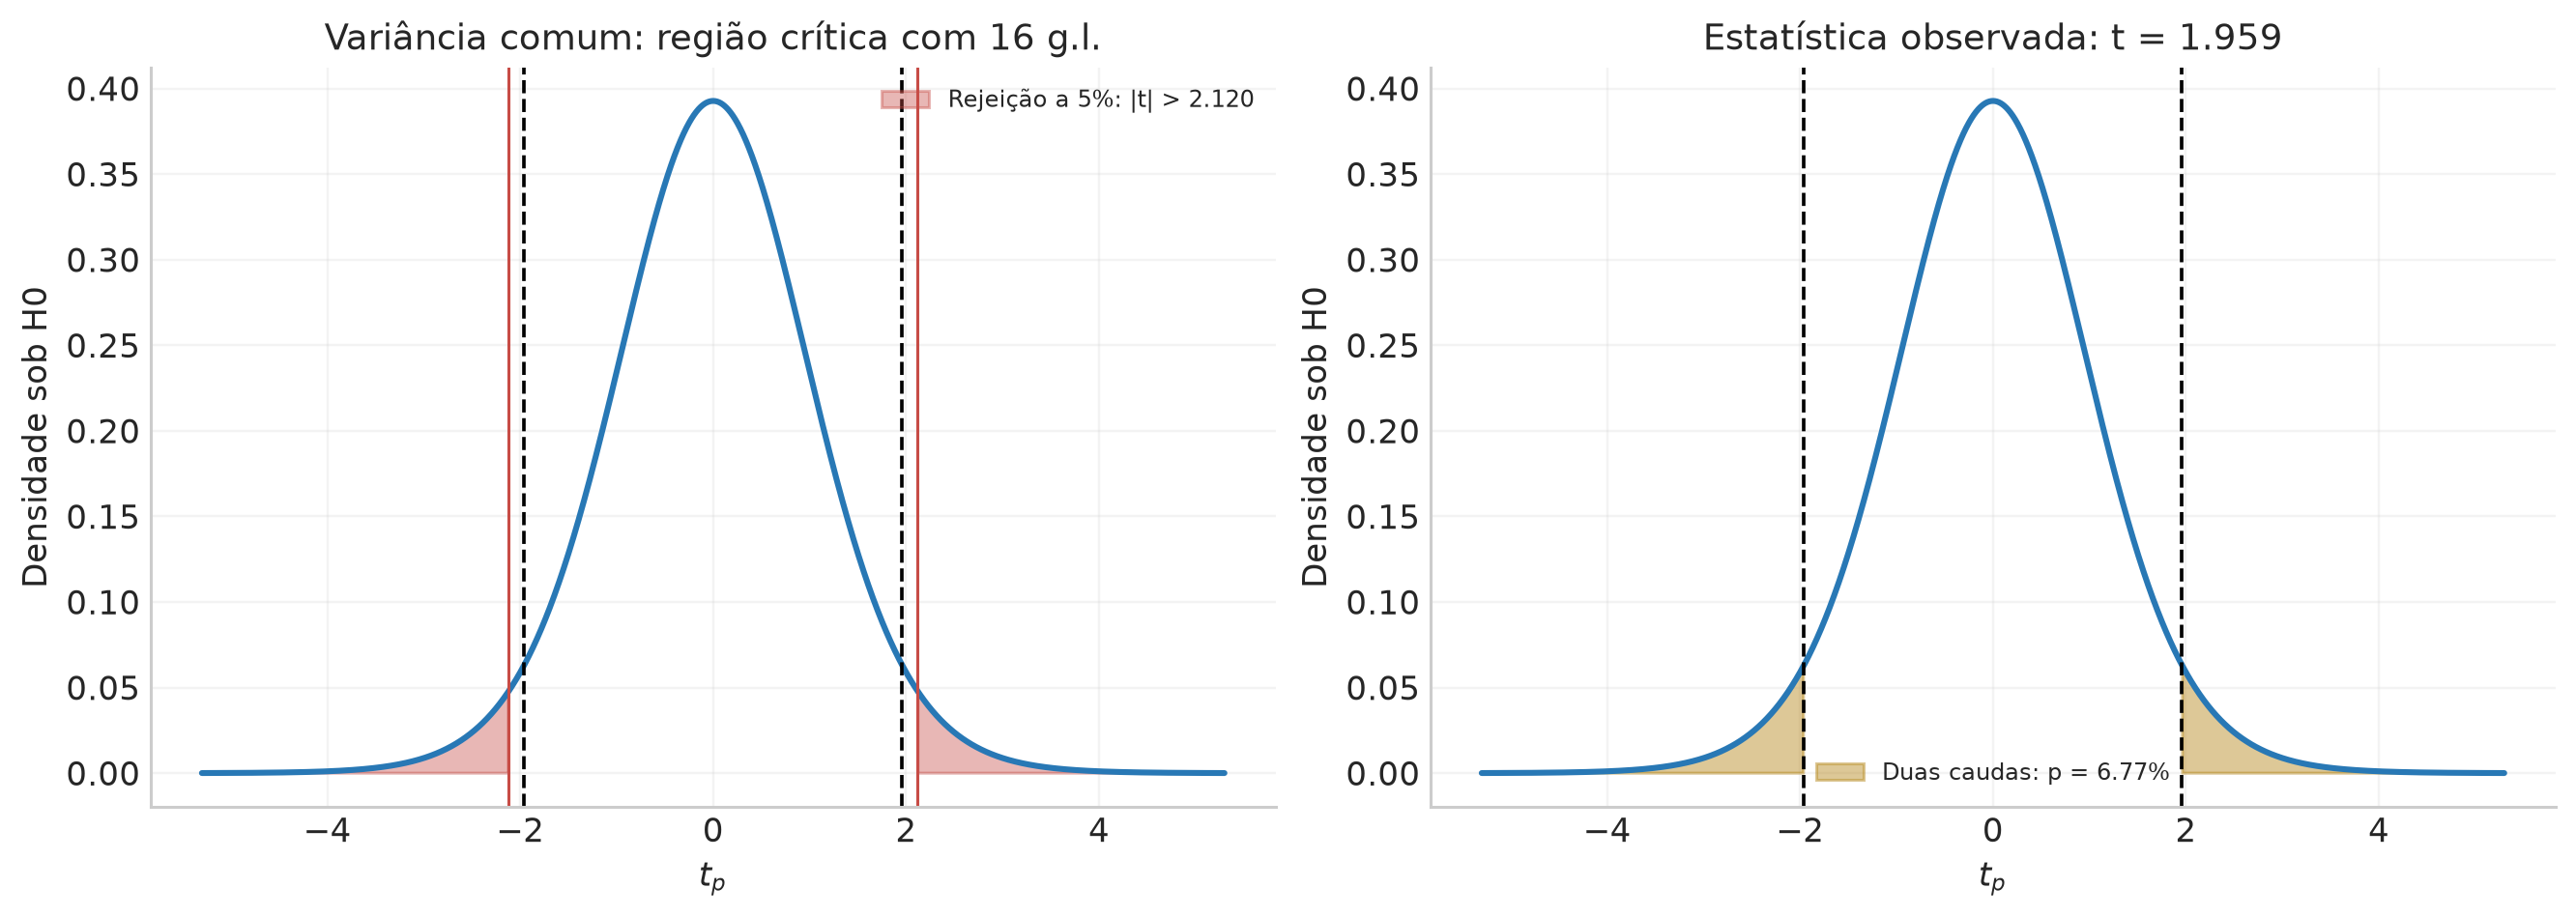

In [9]:
tgrid=np.linspace(-5.3,5.3,2200)
tdens=stats.t.pdf(tgrid,q1_nup)
fig,ax=plt.subplots(1,2,figsize=(12,4.2),layout="constrained")
for a in ax:
    a.plot(tgrid,tdens,color=AZUL)
    for v in [-abs(q1_tp),abs(q1_tp)]:a.axvline(v,color="black",ls="--",lw=1.2)
    a.set(xlabel=r"$t_p$",ylabel="Densidade sob H0")
ax[0].fill_between(tgrid,tdens,where=np.abs(tgrid)>=q1_tcp,color=VERMELHO,alpha=.4,
                   label=f"Rejeição a 5%: |t| > {q1_tcp:.3f}")
for v in [-q1_tcp,q1_tcp]:ax[0].axvline(v,color=VERMELHO,lw=1)
ax[0].set_title("Variância comum: região crítica com 16 g.l.")
ax[1].fill_between(tgrid,tdens,where=np.abs(tgrid)>=abs(q1_tp),color=OURO,alpha=.45,
                   label=f"Duas caudas: p = {100*q1_pp:.2f}%")
ax[1].set_title(f"Estatística observada: t = {q1_tp:.3f}")
for a in ax:a.legend(fontsize=8)
figura(fig,"q1_c_student_variancia_comum")

### Abrindo a substituição numérica

$$s_p^2=\frac{96{,}041+20{,}175}{10+8-2}
=\frac{116{,}216}{16}=7{,}2635\ \mathrm{ppm}^2,$$

$$\operatorname{SE}_p=\sqrt{7{,}2635\left(\frac1{10}+\frac18\right)}
=1{,}2783925\ldots\ \mathrm{ppm},$$

$$t_{p,\rm obs}=\frac{11{,}33-8{,}825}{1{,}2783925\ldots}
=1{,}9594920\ldots.$$

O quantil crítico é $q_{0{,}975}(t_{16})=2{,}1199053\ldots$. O valor observado não alcança essa região. Integrando as duas caudas,

$$\boxed{p_p=0{,}0677144\ldots,\qquad C_{*,p}=93{,}22856\ldots\%.}$$

Portanto, **não rejeitamos médias iguais a 5% sob o modelo de variância comum**. O intervalo correspondente é

$$\boxed{\delta\in[-0{,}205071;\ 5{,}215071]\ \mathrm{ppm}\quad(95\%).}$$

O intervalo contém zero, em concordância com o teste bilateral. Ao mesmo tempo, ele admite diferenças positivas relevantes em unidades de ppm. A conclusão é de incerteza sobre a diferença; não demonstramos igualdade prática entre os locais.

## Item (d) · Comparar as médias sem impor variâncias iguais

As hipóteses sobre as médias continuam $H_{0,\mu}:\delta=0$ e $H_{1,\mu}:\delta\ne0$. Agora $\sigma_1^2$ e $\sigma_2^2$ podem assumir valores diferentes **tanto sob a hipótese nula quanto sob a alternativa**.

Pela independência,

$$\operatorname{Var}(\bar X_1-\bar X_2)
=\frac{\sigma_1^2}{n_1}+\frac{\sigma_2^2}{n_2}.$$

A estimativa direta dessa variância é

$$\widehat V=\frac{S_1^2}{n_1}+\frac{S_2^2}{n_2},\qquad
T_W=\frac{(\bar X_1-\bar X_2)-\delta_0}{\sqrt{\widehat V}}.$$

A dificuldade é que $\widehat V$ soma duas contribuições com escalas diferentes. Em geral, essa soma não é uma única qui-quadrado reescalada; a Student de 16 graus de liberdade deixou de ser exata.

### Por que os graus de liberdade de Welch têm aquela expressão?

Vamos deduzi-los por equivalência dos dois primeiros momentos. Defina

$$a_j=\frac{\sigma_j^2}{n_j},\qquad A_j=\frac{S_j^2}{n_j}.$$

Como $\nu_jS_j^2/\sigma_j^2\sim\chi^2_{\nu_j}$, cujos momentos são média $\nu_j$ e variância $2\nu_j$,

$$\mathbb E[A_j]=a_j,\qquad
\operatorname{Var}(A_j)=\frac{2a_j^2}{\nu_j}.$$

Por independência, a soma $\widehat V=A_1+A_2$ tem

$$v=\mathbb E[\widehat V]=a_1+a_2,\qquad
\operatorname{Var}(\widehat V)=2\left(\frac{a_1^2}{\nu_1}+\frac{a_2^2}{\nu_2}\right).$$

Vamos aproximá-la por $(v/\nu_{\rm ef})U$, com $U\sim\chi^2_{\nu_{\rm ef}}$. Essa variável tem média $v$ e variância $2v^2/\nu_{\rm ef}$. Igualando as variâncias,

$$\nu_{\rm ef}=\frac{(a_1+a_2)^2}{a_1^2/\nu_1+a_2^2/\nu_2}.$$

As variâncias populacionais são desconhecidas. Substituindo-as pelas estimativas amostrais,

$$\boxed{\widehat\nu_W=
\frac{(s_1^2/n_1+s_2^2/n_2)^2}
{(s_1^2/n_1)^2/(n_1-1)+(s_2^2/n_2)^2/(n_2-1)}.}$$

Essa é a aproximação de Welch–Satterthwaite. Os graus de liberdade podem ser não inteiros. Sob normalidade e independência,

$$\boxed{T_W\ \text{é aproximado por}\ t_{\widehat\nu_W}.}$$

O numerador normal continua independente das variâncias amostrais; a aproximação está na distribuição do denominador e no uso dos momentos estimados. Assim, Welch não é um teste exato de Student para quaisquer variâncias.

Para a pergunta bilateral,

$$p_W\simeq2\int_{|t_{W,\rm obs}|}^\infty f_{t_{\widehat\nu_W}}(t)\,dt,$$

e a inversão aproximada produz

$$I_{\delta,W}=\left[(\bar x_1-\bar x_2)\pm
q_{0{,}975}(t_{\widehat\nu_W})\sqrt{s_1^2/n_1+s_2^2/n_2}\right].$$

In [10]:
q1_A = q1_var/q1_n  # Contribuições separadas à variância estimada da diferença.
q1_Vw = q1_A.sum()
q1_sew = np.sqrt(q1_Vw)
q1_nuw = q1_Vw**2/np.sum(q1_A**2/q1_nu)
q1_tw = q1_delta_obs/q1_sew
q1_pw = 2*stats.t.sf(abs(q1_tw),q1_nuw)
q1_tcw = stats.t.ppf(1-q1_alpha/2,q1_nuw)
q1_ciw = q1_delta_obs + np.array([-1,1])*q1_tcw*q1_sew

tabela("q1_d_welch",["s1²/n1", "s2²/n2", "SE (ppm)","nu efetivo", "t observado", "t crítico",
                    "p bilateral", "100(1-p) (%)", "Decisão a 5%"],
       [[*q1_A,q1_sew,q1_nuw,q1_tw,q1_tcw,q1_pw,100*(1-q1_pw),decisao(q1_pw)]],casas=8)
tabela("q1_d_intervalo_diferenca",["Diferença (ppm)","IC 95% inferior (ppm)","IC 95% superior (ppm)"],
       [[q1_delta_obs,*q1_ciw]],casas=7)
q1_scipy_w = stats.ttest_ind(q1_x1,q1_x2,equal_var=False,alternative="two-sided")
conferir("Welch: estatística, p e graus de liberdade coincidem com SciPy",
         np.allclose([q1_tw,q1_pw,q1_nuw],[q1_scipy_w.statistic,q1_scipy_w.pvalue,q1_scipy_w.df]))
conferir("Welch: IC da diferença coincide com SciPy",np.allclose(q1_ciw,q1_scipy_w.confidence_interval()))
conferir("Welch: integral da cauda coincide com sf",np.isclose(q1_pw,
         2*integrate.quad(lambda t:stats.t.pdf(t,q1_nuw),abs(q1_tw),np.inf)[0]))

| s1²/n1 | s2²/n2 | SE (ppm) | nu efetivo | t observado | t crítico | p bilateral | 100(1-p) (%) | Decisão a 5% |
| :-- | :-- | :-- | :-- | :-- | :-- | :-- | :-- | :-- |
| 1,06712222 | 0,36026786 | 1,19473431 | 14,04458512 | 2,09670047 | 2,14414810 | 0,05460470 | 94,53953023 | Não rejeitar H0 |

| Diferença (ppm) | IC 95% inferior (ppm) | IC 95% superior (ppm) |
| :-- | :-- | :-- |
| 2,5050000 | -0,0566873 | 5,0666873 |

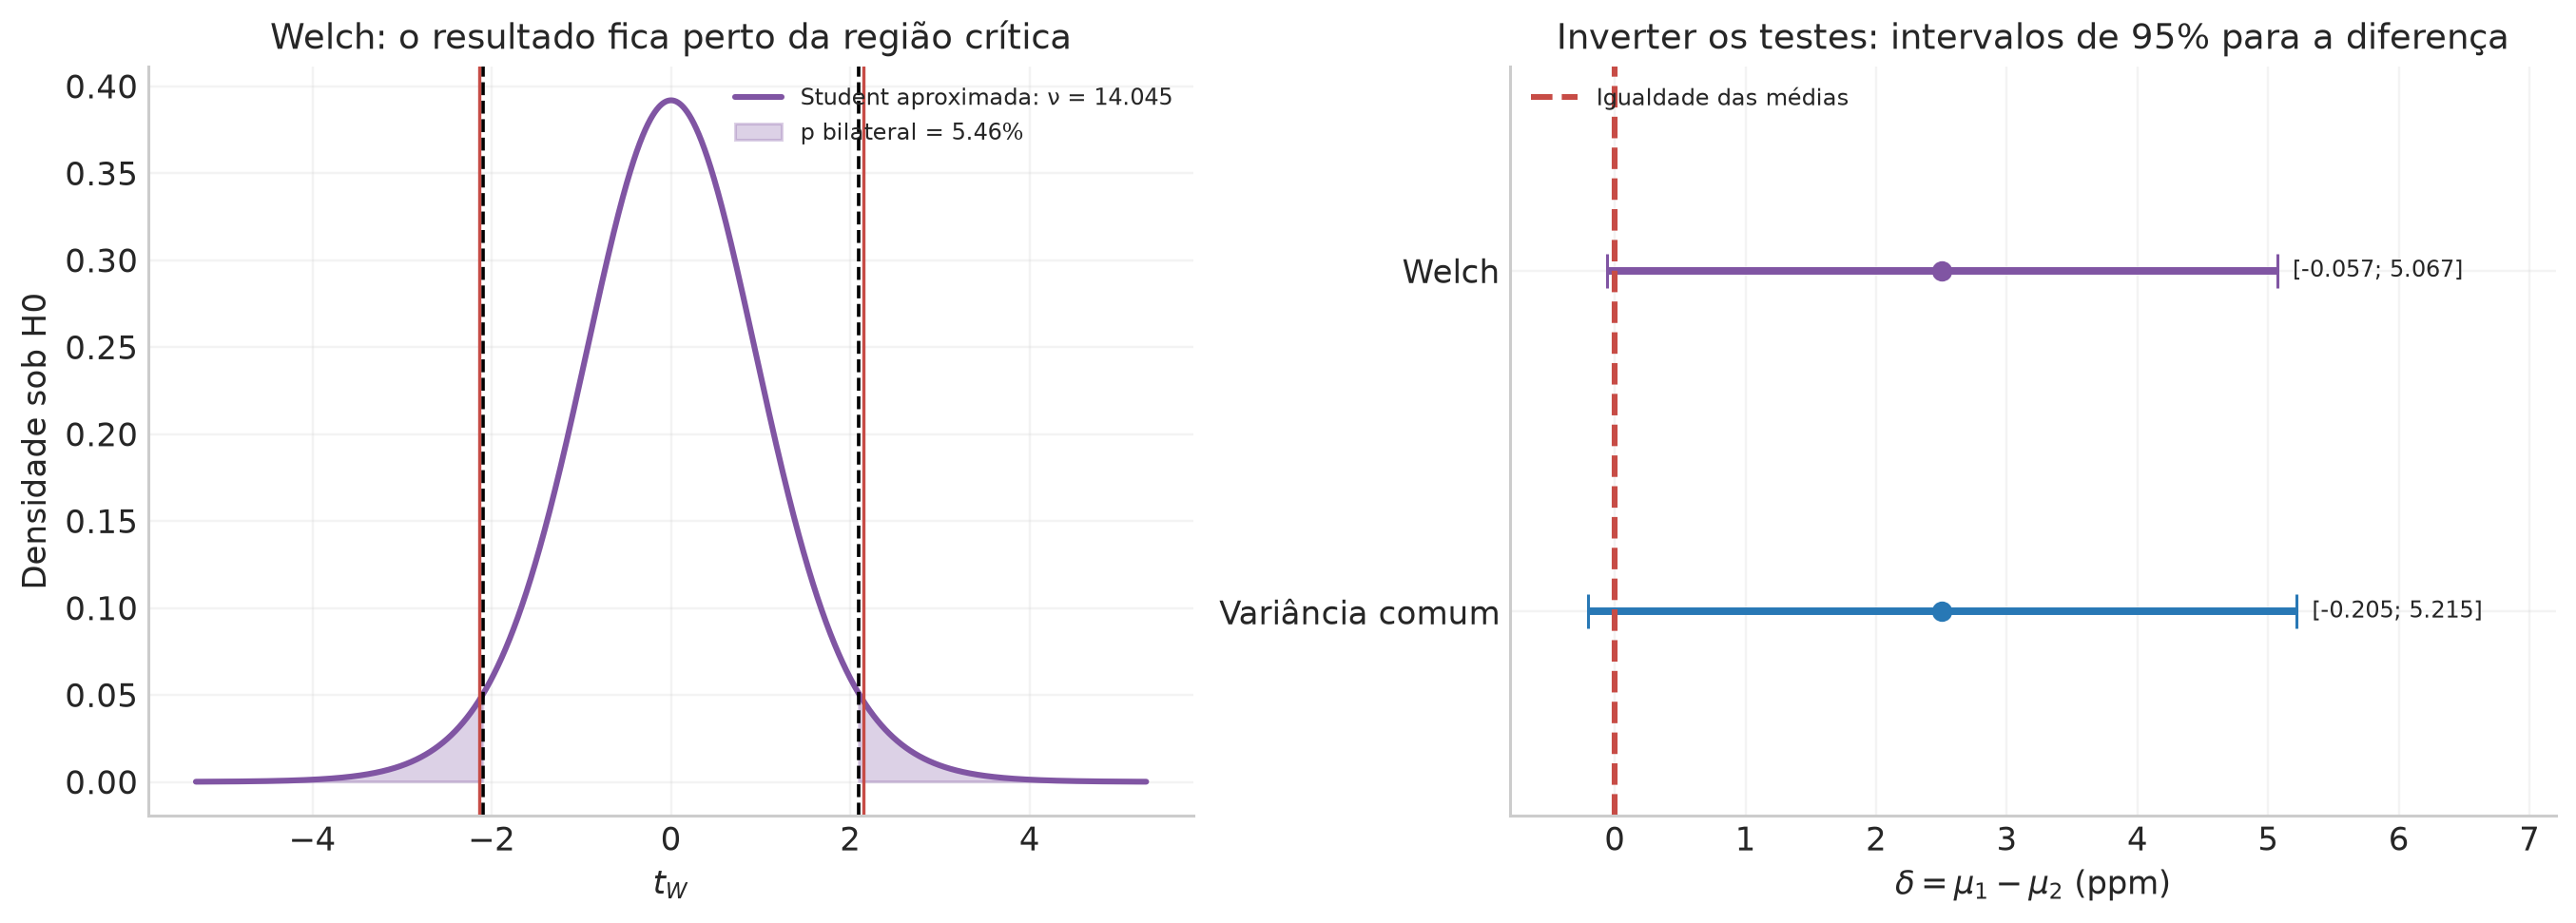

In [11]:
fig,ax=plt.subplots(1,2,figsize=(12.2,4.3),layout="constrained")
dens=stats.t.pdf(tgrid,q1_nuw)
ax[0].plot(tgrid,dens,color=ROXO,label=f"Student aproximada: ν = {q1_nuw:.3f}")
ax[0].fill_between(tgrid,dens,where=np.abs(tgrid)>=abs(q1_tw),color=ROXO,alpha=.27,
                   label=f"p bilateral = {100*q1_pw:.2f}%")
for v in [-abs(q1_tw),abs(q1_tw)]:ax[0].axvline(v,color="black",ls="--",lw=1.2)
for v in [-q1_tcw,q1_tcw]:ax[0].axvline(v,color=VERMELHO,lw=1.1)
ax[0].set(xlabel=r"$t_W$",ylabel="Densidade sob H0",title="Welch: o resultado fica perto da região crítica")
ax[0].legend(fontsize=8)
for j,(ci,cor,nome) in enumerate([(q1_cip,AZUL,"Variância comum"),(q1_ciw,ROXO,"Welch")]):
    ax[1].errorbar(q1_delta_obs,j,xerr=np.array([[q1_delta_obs-ci[0]],[ci[1]-q1_delta_obs]]),
                   fmt="o",color=cor,capsize=6,lw=2.6)
    ax[1].text(ci[1]+.12,j,f"[{ci[0]:.3f}; {ci[1]:.3f}]",va="center",fontsize=8)
ax[1].axvline(0,color=VERMELHO,ls="--",label="Igualdade das médias")
ax[1].set(yticks=[0,1],yticklabels=["Variância comum","Welch"],ylim=(-.6,1.6),
          xlim=(-.8,7.2),xlabel=r"$\delta=\mu_1-\mu_2$ (ppm)",title="Inverter os testes: intervalos de 95% para a diferença")
ax[1].legend(loc="upper left",fontsize=8)
figura(fig,"q1_d_welch_e_intervalos_diferenca")

### Resultado de Welch e comparação com o item (c)

As contribuições à variância da diferença são

$$\frac{s_1^2}{n_1}=1{,}0671222\ldots\ \mathrm{ppm}^2,\qquad
\frac{s_2^2}{n_2}=0{,}3602679\ldots\ \mathrm{ppm}^2.$$

Logo,

$$\widehat V=1{,}4273901\ldots\ \mathrm{ppm}^2,\qquad
\operatorname{SE}_W=1{,}1947343\ldots\ \mathrm{ppm},$$

$$\widehat\nu_W=
\frac{(1{,}0671222\ldots+0{,}3602679\ldots)^2}
{(1{,}0671222\ldots)^2/9+(0{,}3602679\ldots)^2/7}
=14{,}0445851\ldots,$$

$$t_{W,\rm obs}=\frac{2{,}505}{1{,}1947343\ldots}=2{,}0967005\ldots.$$

Integrando a Student aproximada,

$$\boxed{p_W\simeq0{,}0546047,\qquad C_{*,W}\simeq94{,}53953\%.}$$

O intervalo aproximado é

$$\boxed{\delta\in[-0{,}056687;\ 5{,}066687]\ \mathrm{ppm}\quad(95\%).}$$

**Também não rejeitamos médias iguais a 5%**, agora sem impor variâncias comuns. O resultado está próximo do limiar, mas $p=0{,}0546$ não será arredondado para uma rejeição. A regra foi definida antes do cálculo.

Por que Welch produziu um valor-p menor? Nesta amostra, sua estimativa do erro da diferença é menor: $1{,}1947$ ppm, contra $1{,}2784$ ppm no modelo combinado. O local de maior variância é também o que tem mais medidas; o método combinado aplica a variância comum ao local 2, menor e menos disperso. O efeito líquido aqui aumenta o erro combinado. Em outras amostras, a relação pode ser diferente: Welch não é uma maneira de escolher sempre o menor valor-p.

Se não tivéssemos justificativa substantiva para impor variâncias iguais, Welch seria a análise mais flexível para a comparação das médias entre as duas opções calculadas. Nesta lista, apresentamos ambas porque o enunciado pede explicitamente as duas hipóteses.

## Síntese dos resultados · 

Nos três testes, as alternativas foram bilaterais. As distribuições de referência vieram das hipóteses; os valores-p foram calculados depois. A tabela reúne os resultados sem transformá-los em probabilidades posteriores de modelos.

| Pergunta | Estatística | Graus de liberdade | p bilateral | 100(1-p) (%) | Decisão com alpha=5% |
| :-- | :-- | :-- | :-- | :-- | :-- |
| Variâncias: F bilateral | 3,7025306 | 9 e 7 | 0,0982986 | 90,1701414 | Não rejeitar H0 |
| Médias: variância comum | 1,9594920 | 16 | 0,0677144 | 93,2285598 | Não rejeitar H0 |
| Médias: Welch | 2,0967005 | 14.044585 (aprox.) | 0,0546047 | 94,5395302 | Não rejeitar H0 |

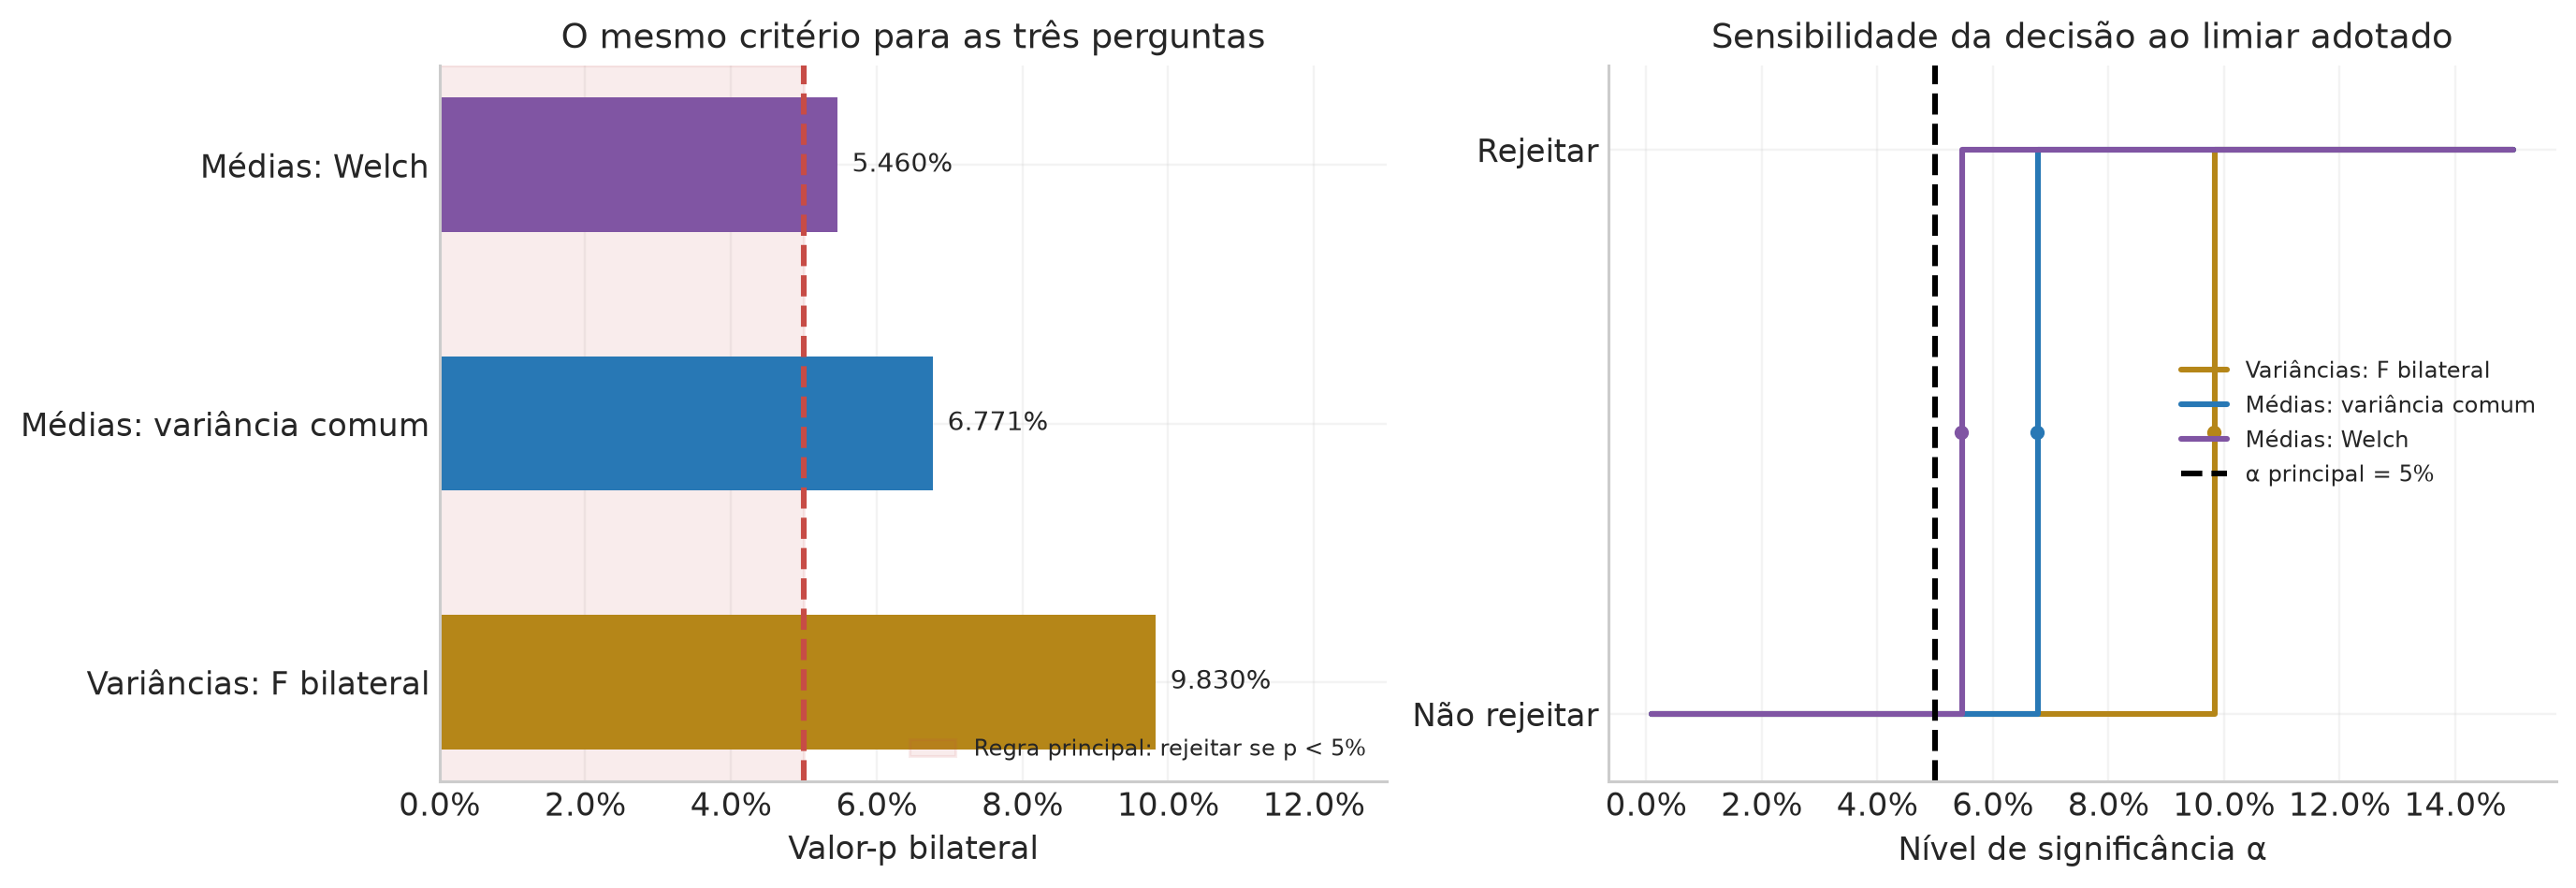

In [12]:
q1_ps = np.array([q1_pF,q1_pp,q1_pw])
q1_rotulos = ["Variâncias: F bilateral", "Médias: variância comum", "Médias: Welch"]
tabela("q1_sintese_testes",["Pergunta", "Estatística", "Graus de liberdade", "p bilateral",
                           "100(1-p) (%)", "Decisão com alpha=5%"],
       [[q1_rotulos[0],q1_Fobs,"9 e 7",q1_pF,100*(1-q1_pF),decisao(q1_pF)],
        [q1_rotulos[1],q1_tp,"16",q1_pp,100*(1-q1_pp),decisao(q1_pp)],
        [q1_rotulos[2],q1_tw,f"{q1_nuw:.6f} (aprox.)",q1_pw,100*(1-q1_pw),decisao(q1_pw)]],casas=7)

fig,ax=plt.subplots(1,2,figsize=(12.4,4.2),layout="constrained")
ys=np.arange(3)
ax[0].axvspan(0,q1_alpha,color=VERMELHO,alpha=.1,label="Regra principal: rejeitar se p < 5%")
ax[0].barh(ys,q1_ps,color=[OURO,AZUL,ROXO],height=.52)
for y,p in zip(ys,q1_ps):ax[0].text(p+.002,y,f"{100*p:.3f}%",va="center",fontsize=9)
ax[0].axvline(q1_alpha,color=VERMELHO,ls="--")
ax[0].set(yticks=ys,yticklabels=q1_rotulos,xlim=(0,.13),xlabel="Valor-p bilateral",
          title="O mesmo critério para as três perguntas")
ax[0].xaxis.set_major_formatter(PercentFormatter(1))
ax[0].legend(loc="lower right",fontsize=8)
for p,cor,rot in zip(q1_ps,[OURO,AZUL,ROXO],q1_rotulos):
    aa=np.linspace(.001,.15,500)
    ax[1].step(aa,(p<aa).astype(int),where="post",color=cor,label=rot)
    ax[1].plot(p,.5,"o",color=cor,ms=4)
ax[1].axvline(q1_alpha,color="black",ls="--",label="α principal = 5%")
ax[1].set(yticks=[0,1],yticklabels=["Não rejeitar","Rejeitar"],ylim=(-.12,1.15),
          xlabel="Nível de significância α",title="Sensibilidade da decisão ao limiar adotado")
ax[1].xaxis.set_major_formatter(PercentFormatter(1))
ax[1].legend(fontsize=8,loc="center right")
figura(fig,"q1_sintese_criterio_objetivo")

for p,ci in [(q1_pp,q1_cip),(q1_pw,q1_ciw)]:
    conferir("Dualidade teste/intervalo para a diferença de médias",
             (p<q1_alpha)==(not(ci[0]<=0<=ci[1])))

As médias amostrais são $11{,}33$ e $8{,}825$ ppm, e as variâncias amostrais são $10{,}671222$ e $2{,}882143$ ppm². Os intervalos individuais de 95% foram construídos com Student para as médias e qui-quadrado para as variâncias. No teste bilateral das variâncias, $F=3{,}702531$ e $p=0{,}098299$. Para as médias, o modelo de variância comum fornece $t=1{,}959492$, com 16 graus de liberdade e $p=0{,}067714$; Welch fornece $t=2{,}096700$, com aproximadamente $14{,}044585$ graus de liberdade e $p=0{,}054605$. Nenhuma dessas hipóteses nulas é rejeitada ao nível de 5%. Os valores de $100(1-p)$ solicitados pela linguagem do exercício são, respectivamente, $90{,}17014\%$, $93{,}22856\%$ e $94{,}53953\%$; eles não são probabilidades posteriores das alternativas.

Até aqui, os itens **(a)–(d) estão resolvidos**. As duas explorações seguintes verificam a cobertura dos procedimentos e respondem à pergunta adicional sobre probabilidades dos quatro modelos.

## Extensão bayesiana · Quanto pesa cada combinação de médias e escalas?

O gráfico de quatro cores que fizemos no capítulo 9 comparava probabilidades posteriores de modelos. Vamos reconstruir essa ideia **com os dados desta questão**, sem usar os valores-p como se fossem essas probabilidades.

Um valor-p descreve resultados possíveis do experimento condicionados a uma hipótese nula. Para calcular $P(M\mid D)$, precisamos também definir modelos alternativos, priors dos parâmetros e probabilidades anteriores dos modelos. Esta extensão acrescenta essas escolhas; ela não integra o pedido original do problema 7.2.

### Os quatro modelos

O primeiro índice indica se as médias são livres para diferir; o segundo faz o mesmo para as escalas:

| Modelo | Médias | Desvios padrão | Parâmetros livres |
|:--|:--|:--|:--|
| $M_{00}$ | Uma média comum | Uma escala comum | $\mu,\sigma$ |
| $M_{10}$ | Duas médias | Uma escala comum | $\mu_1,\mu_2,\sigma$ |
| $M_{01}$ | Uma média comum | Duas escalas | $\mu,\sigma_1,\sigma_2$ |
| $M_{11}$ | Duas médias | Duas escalas | $\mu_1,\mu_2,\sigma_1,\sigma_2$ |

“Médias livres” permite valores distintos. Com priors contínuas independentes nesse modelo, a igualdade exata tem probabilidade zero. Para atribuir massa à hipótese de igualdade, ela aparece nos modelos com uma média comum. O mesmo raciocínio vale para as escalas.

### Especificar e normalizar as priors

Para cada média livre, adotamos $\mathcal U[L,H]$; para cada desvio padrão livre, uma prior de escala proporcional a $1/\sigma$, restrita a $[a,b]$:

$$\pi(\mu)=\frac1{R}\mathbf1_{[L,H]}(\mu),\quad R=H-L,
\qquad
\pi(\sigma)=\frac1{\ell\sigma}\mathbf1_{[a,b]}(\sigma),\quad\ell=\log(b/a).$$

As normalizações vêm de $\int_L^H d\mu=R$ e $\int_a^b d\sigma/\sigma=\ell$. Cada parâmetro livre recebe seu próprio fator de prior. Um parâmetro comum aparece uma única vez; não multiplicamos duas priors para a mesma variável.

Usaremos $P(M_k)=1/4$ e dois cenários ilustrativos de intervalos, inspirados nos exemplos de sensibilidade do Gregory:

| Cenário | Intervalo de cada média, em ppm | Intervalo de cada desvio padrão, em ppm |
|:--|:--|:--|
| A: amplo | $[2,18]$ | $[0{,}4,10]$ |
| B: concentrado | $[7,12]$ | $[1,4]$ |

Esses intervalos são **hipóteses anteriores adicionais**, não intervalos de confiança obtidos nos itens anteriores. O cenário concentrado modifica tanto o volume quanto as fronteiras da prior. Não vamos escolhê-lo pelo modelo que ele favorecer; os dois servem para mostrar a dependência da comparação de modelos em relação à informação anterior.

### Da distribuição dos erros à likelihood de cada grupo

O modelo normal do enunciado pode ser escrito como

$$X_{ji}=\mu_j+\varepsilon_{ji},\qquad
\varepsilon_{ji}\overset{\mathrm{ind}}\sim\mathcal N(0,\sigma_j^2).$$

Para parâmetros fixos, os dados têm a mesma distribuição dos erros, deslocada por $\mu_j$. Pela independência, multiplicamos as densidades das medidas:

$$\mathcal L_j(\mu_j,\sigma_j)=
\prod_{i=1}^{n_j}\frac{1}{\sqrt{2\pi}\sigma_j}
\exp\left[-\frac{(x_{ji}-\mu_j)^2}{2\sigma_j^2}\right].$$

Para separar os dados dos parâmetros, usamos

$$\begin{aligned}
\sum_i(x_{ji}-\mu_j)^2
&=\sum_i[(x_{ji}-\bar x_j)+(\bar x_j-\mu_j)]^2\\
&=Q_j+2(\bar x_j-\mu_j)\underbrace{\sum_i(x_{ji}-\bar x_j)}_{0}
+n_j(\bar x_j-\mu_j)^2\\
&=Q_j+n_j(\mu_j-\bar x_j)^2.
\end{aligned}$$

Logo,

$$\boxed{\mathcal L_j(\mu_j,\sigma_j)=
(2\pi)^{-n_j/2}\sigma_j^{-n_j}
\exp\left[-\frac{Q_j+n_j(\mu_j-\bar x_j)^2}{2\sigma_j^2}\right].}$$

A likelihood conjunta é $\mathcal L_1\mathcal L_2$, com as igualdades de parâmetros impostas por cada modelo. Vamos manter as normalizações: a evidência é uma integral de likelihood contra prior, não apenas o valor do melhor ajuste.

### Integrar uma média livre: primeira peça da evidência

Para uma escala $s$ fixa, defina a integral **sem o fator de prior**

$$A_j(s)=\int_L^H\mathcal L_j(\mu,s)\,d\mu.$$

Faça $z=(\mu-\bar x_j)/(s/\sqrt{n_j})$, com $d\mu=(s/\sqrt{n_j})dz$. Se $\Phi$ é a CDF normal padrão,

$$\int_L^H e^{-n_j(\mu-\bar x_j)^2/(2s^2)}\,d\mu
=\sqrt{2\pi}\frac{s}{\sqrt{n_j}}
\left[\Phi\left(\frac{H-\bar x_j}{s/\sqrt{n_j}}\right)
-\Phi\left(\frac{L-\bar x_j}{s/\sqrt{n_j}}\right)\right].$$

Chamando o termo entre colchetes de $\Delta\Phi_j(s)$,

$$\boxed{A_j(s)=
(2\pi)^{-n_j/2}s^{-n_j}e^{-Q_j/(2s^2)}
\sqrt{2\pi}\frac{s}{\sqrt{n_j}}\Delta\Phi_j(s).}$$

Preservar $\Delta\Phi_j$ incorpora exatamente os limites da prior; não estamos supondo que o pico inteiro esteja longe das fronteiras.

### Integrar uma média comum: segunda peça

Agora as escalas $s_1,s_2$ são fixas e a média é a mesma. Precisamos de

$$B(s_1,s_2)=\int_L^H\mathcal L_1(\mu,s_1)\mathcal L_2(\mu,s_2)\,d\mu.$$

Defina $w_j=n_j/s_j^2$, $W=w_1+w_2$ e

$$m=\frac{w_1\bar x_1+w_2\bar x_2}{W}.$$

Completando o quadrado,

$$w_1(\mu-\bar x_1)^2+w_2(\mu-\bar x_2)^2
=W(\mu-m)^2+\frac{w_1w_2}{W}(\bar x_1-\bar x_2)^2.$$

Podemos conferir expandindo os dois lados em potências de $\mu$: os termos quadrático e linear coincidem, e o termo independente restante é o custo de impor uma média comum. Assim,

$$K=\frac{Q_1}{s_1^2}+\frac{Q_2}{s_2^2}
+\frac{w_1w_2}{W}(\bar x_1-\bar x_2)^2,$$

$$\boxed{B(s_1,s_2)=
(2\pi)^{-N/2}s_1^{-n_1}s_2^{-n_2}e^{-K/2}
\sqrt{\frac{2\pi}{W}}\left[\Phi((H-m)\sqrt W)-\Phi((L-m)\sqrt W)\right],}$$

com $N=n_1+n_2=18$. A conta usa a mesma integral normal da etapa anterior, agora com centro $m$ e largura $1/\sqrt W$.

### Montar as quatro evidências, com todos os fatores de prior

A evidência de um modelo é $Z_k=P(D\mid M_k)=\int\mathcal L_k(\theta)\pi_k(\theta)\,d\theta$. Para integrar as escalas, usamos $\eta=\log(s/s_0)$, com $s_0=1$ ppm fixo. Numericamente, isso equivale a tomar o logaritmo do valor de $s$ em ppm; $s=s_0e^\eta$ e $ds/s=d\eta$. Seja $\eta_a=\log(a/s_0)$ e $\eta_b=\log(b/s_0)$.

$$\boxed{\begin{aligned}
Z_{00}&=\frac1{R\ell}\int_{\eta_a}^{\eta_b}B(s_0e^\eta,s_0e^\eta)\,d\eta,\\
Z_{10}&=\frac1{R^2\ell}\int_{\eta_a}^{\eta_b}A_1(s_0e^\eta)A_2(s_0e^\eta)\,d\eta,\\
Z_{01}&=\frac1{R\ell^2}\int_{\eta_a}^{\eta_b}\int_{\eta_a}^{\eta_b}
B(s_0e^{\eta_1},s_0e^{\eta_2})\,d\eta_1\,d\eta_2,\\
Z_{11}&=\frac1{R^2\ell^2}
\left[\int_{\eta_a}^{\eta_b}A_1(s_0e^{\eta_1})\,d\eta_1\right]
\left[\int_{\eta_a}^{\eta_b}A_2(s_0e^{\eta_2})\,d\eta_2\right].
\end{aligned}}$$

Em $M_{10}$, as médias se integram separadamente **condicionadas à mesma escala**; por isso o produto $A_1A_2$ fica dentro de uma única integral. Em $M_{11}$, todos os parâmetros dos grupos são independentes na prior e a evidência fatoriza. Em $M_{01}$, a média comum conecta os grupos mesmo que as escalas sejam livres.

Calcularemos as integrais restantes por quadratura de Gauss–Legendre. Os nós e pesos em $[-1,1]$ são transformados para $[\eta_a,\eta_b]$; uma integral vira uma soma ponderada, e uma integral dupla vira uma soma dupla. Repetiremos com mais nós para verificar a estabilidade.

In [13]:
def q1_gl(a,b,nos=100):
    """Nós e pesos de Gauss–Legendre transportados de [-1,1] para [a,b]."""
    z,w=leggauss(nos)
    return a+(z+1)*(b-a)/2, w*(b-a)/2

def q1_delta_phi(lo,hi,centro,escala):
    """Integral de uma normal entre lo e hi, usando sua CDF."""
    return special.ndtr((hi-centro)/escala)-special.ndtr((lo-centro)/escala)

def q1_Aj(j,s,L,H):
    """Integral da likelihood do grupo j sobre sua média; sem a prior 1/R."""
    n,m,Q=q1_n[j],q1_media[j],q1_Q[j]
    return ((2*np.pi)**(-n/2)*s**(-n)*np.exp(-Q/(2*s*s))
            *np.sqrt(2*np.pi)*s/np.sqrt(n)*q1_delta_phi(L,H,m,s/np.sqrt(n)))

def q1_Bcomum(s1,s2,L,H):
    """Integral em uma média comum; sem os fatores de prior."""
    n1,n2=q1_n
    w1,w2=n1/s1**2,n2/s2**2
    W=w1+w2
    m=(w1*q1_media[0]+w2*q1_media[1])/W
    K=q1_Q[0]/s1**2+q1_Q[1]/s2**2+w1*w2/W*q1_delta_obs**2
    return ((2*np.pi)**(-(n1+n2)/2)*s1**(-n1)*s2**(-n2)*np.exp(-K/2)
            *np.sqrt(2*np.pi/W)*q1_delta_phi(L,H,m,1/np.sqrt(W)))

def q1_evidencias(L,H,a,b,nos=100):
    """Z00, Z10, Z01, Z11: priors próprias, médias integradas analiticamente."""
    assert L<H and 0<a<b
    R,ell=H-L,np.log(b/a)
    eta,w=q1_gl(np.log(a),np.log(b),nos)  # Escalas numéricas em ppm; s0=1 ppm.
    s=np.exp(eta)
    A1,A2=q1_Aj(0,s,L,H),q1_Aj(1,s,L,H)
    Z00=np.dot(w,q1_Bcomum(s,s,L,H))/(R*ell)
    Z10=np.dot(w,A1*A2)/(R**2*ell)
    Z01=np.einsum("i,ij,j->",w,q1_Bcomum(s[:,None],s[None,:],L,H),w)/(R*ell**2)
    Z11=np.dot(w,A1)*np.dot(w,A2)/(R**2*ell**2)
    return np.array([Z00,Z10,Z01,Z11])

q1_prior_modelos=np.full(4,.25)
q1_cenarios={"A: amplo":(2.,18.,.4,10.), "B: concentrado":(7.,12.,1.,4.)}
q1_Zs,q1_Ps={},{}
for nome,lim in q1_cenarios.items():
    zz=q1_evidencias(*lim,nos=100)
    logpesos=np.log(zz)+np.log(q1_prior_modelos)
    pp=np.exp(logpesos-special.logsumexp(logpesos))
    q1_Zs[nome],q1_Ps[nome]=zz,pp
    conferir(f"Evidências positivas: {nome}",np.all(np.isfinite(zz)) and np.all(zz>0))
    conferir(f"Probabilidades dos modelos somam um: {nome}",np.isclose(pp.sum(),1))
    conferir(f"Quadratura 100 e 180 nós: {nome}",np.allclose(zz,q1_evidencias(*lim,nos=180),rtol=2e-9))

tabela("q1_extra_evidencias",["Cenário","Modelo","Evidência (densidade)","log Z","Prior do modelo","Posterior"],
       [[nome,rot,f"{z:.10e}",np.log(z),q1_prior_modelos[k],q1_Ps[nome][k]]
        for nome,zs in q1_Zs.items() for k,(rot,z) in enumerate(zip(["M00","M10","M01","M11"],zs))],casas=8)

| Cenário | Modelo | Evidência (densidade) | log Z | Prior do modelo | Posterior |
| :-- | :-- | :-- | :-- | :-- | :-- |
| A: amplo | M00 | 8.5537718540e-22 | -48,51049971 | 0,25000000 | 0,19428868 |
| A: amplo | M10 | 1.0828897683e-21 | -48,27465377 | 0,25000000 | 0,24596544 |
| A: amplo | M01 | 1.0691741871e-21 | -48,28740039 | 0,25000000 | 0,24285011 |
| A: amplo | M11 | 1.3951683786e-21 | -48,02127184 | 0,25000000 | 0,31689578 |
| B: concentrado | M00 | 5.9316520346e-21 | -46,57398419 | 0,25000000 | 0,07667004 |
| B: concentrado | M10 | 1.8803176673e-20 | -45,42026113 | 0,25000000 | 0,24304196 |
| B: concentrado | M01 | 1.0625625827e-20 | -45,99101834 | 0,25000000 | 0,13734238 |
| B: concentrado | M11 | 4.2005513531e-20 | -44,61648607 | 0,25000000 | 0,54294562 |

### Das evidências às probabilidades dos quatro modelos

Aplicando Bayes ao índice discreto do modelo,

$$\boxed{P(M_k\mid D)=\frac{Z_kP(M_k)}{\sum_\ell Z_\ell P(M_\ell)}.}$$

As evidências têm unidades de densidade dos mesmos 18 dados, ppm$^{-18}$. Valores pequenos de $Z$ não são probabilidades pequenas de um modelo; o que entra na atualização são suas razões e as priors dos modelos. O código usa logaritmos para normalizar esses pesos.

Com priors iguais, $P(M_k\mid D)=Z_k/\sum_\ell Z_\ell$. Para perguntar se as médias são comuns, somamos os dois modelos que impõem essa restrição:

$$\begin{aligned}
P(\text{média comum}\mid D)&=P(M_{00}\mid D)+P(M_{01}\mid D),\\
P(\text{médias livres}\mid D)&=P(M_{10}\mid D)+P(M_{11}\mid D),\\
P(\text{escala comum}\mid D)&=P(M_{00}\mid D)+P(M_{10}\mid D),\\
P(\text{escalas livres}\mid D)&=P(M_{01}\mid D)+P(M_{11}\mid D).
\end{aligned}$$

Cada par soma 1. Já a pergunta “ao menos uma diferença” agrupa três modelos:

$$P(\text{ao menos uma diferença}\mid D)=1-P(M_{00}\mid D).$$

Sua probabilidade anterior é $3/4$, porque cada um dos quatro modelos recebeu prior $1/4$. É importante mostrar essa referência para não atribuir todo o peso posterior desse grupo apenas aos dados.

Para qualquer comparação entre dois grupos exaustivos, o fator de Bayes é a razão das odds posteriores pelas anteriores:

$$B_{A:\bar A}=\frac{P(A\mid D)/P(\bar A\mid D)}{P(A)/P(\bar A)}.$$

Para médias livres versus comuns e para escalas livres versus comuns, as odds anteriores são 1. Para “ao menos uma diferença” versus $M_{00}$, elas são 3. A tabela abaixo faz essas contas explicitamente.

In [14]:
q1_agregadas=[]
for nome,pp in q1_Ps.items():
    probs=[pp[1]+pp[3],pp[2]+pp[3],1-pp[0]]
    priors=[.5,.5,.75]
    for pergunta,p,pi in zip(["Médias livres","Escalas livres","Ao menos uma diferença"],probs,priors):
        odds_post=p/(1-p)
        odds_prior=pi/(1-pi)
        q1_agregadas.append([nome,pergunta,pi,p,odds_post,odds_post/odds_prior])
tabela("q1_extra_probabilidades_agregadas",["Cenário","Pergunta","Prior","Posterior","Odds posteriores","Fator de Bayes"],
       q1_agregadas,casas=7)

# Conferências por integração independente, sem as fórmulas gaussianas integradas.
L,H,a,b=q1_cenarios["A: amplo"]
s_teste=3.
def q1_Lj(mu,s,j):
    return (2*np.pi)**(-q1_n[j]/2)*s**(-q1_n[j])*np.exp(
        -(q1_Q[j]+q1_n[j]*(mu-q1_media[j])**2)/(2*s*s))
for j in range(2):
    ref=q1_Aj(j,s_teste,L,H)
    numerica=integrate.quad(lambda mu:q1_Lj(mu,s_teste,j)/ref,L,H,epsabs=1e-10)[0]
    conferir(f"Integral A{j+1}: fórmula analítica versus quad",np.isclose(numerica,1,rtol=1e-10))
refB=q1_Bcomum(3.,2.,L,H)
numerica=integrate.quad(lambda mu:q1_Lj(mu,3.,0)*q1_Lj(mu,2.,1)/refB,L,H,epsabs=1e-10)[0]
conferir("Integral B: fórmula analítica versus quad",np.isclose(numerica,1,rtol=1e-10))
mus,wm=q1_gl(L,H,120)
etas,we=q1_gl(np.log(a),np.log(b),140)
ss=np.exp(etas)[None,:]
Z00_direta=np.einsum("i,ij,j->",wm,q1_Lj(mus[:,None],ss,0)*q1_Lj(mus[:,None],ss,1),we)/((H-L)*np.log(b/a))
conferir("Z00: quadratura direta em média e log escala",
         np.isclose(Z00_direta,q1_Zs["A: amplo"][0],rtol=1e-9))

| Cenário | Pergunta | Prior | Posterior | Odds posteriores | Fator de Bayes |
| :-- | :-- | :-- | :-- | :-- | :-- |
| A: amplo | Médias livres | 0,5000000 | 0,5628612 | 1,2876030 | 1,2876030 |
| A: amplo | Escalas livres | 0,5000000 | 0,5597459 | 1,2714155 | 1,2714155 |
| A: amplo | Ao menos uma diferença | 0,7500000 | 0,8057113 | 4,1469803 | 1,3823268 |
| B: concentrado | Médias livres | 0,5000000 | 0,7859876 | 3,6726261 | 3,6726261 |
| B: concentrado | Escalas livres | 0,5000000 | 0,6802880 | 2,1278150 | 2,1278150 |
| B: concentrado | Ao menos uma diferença | 0,7500000 | 0,9233300 | 12,0429040 | 4,0143013 |

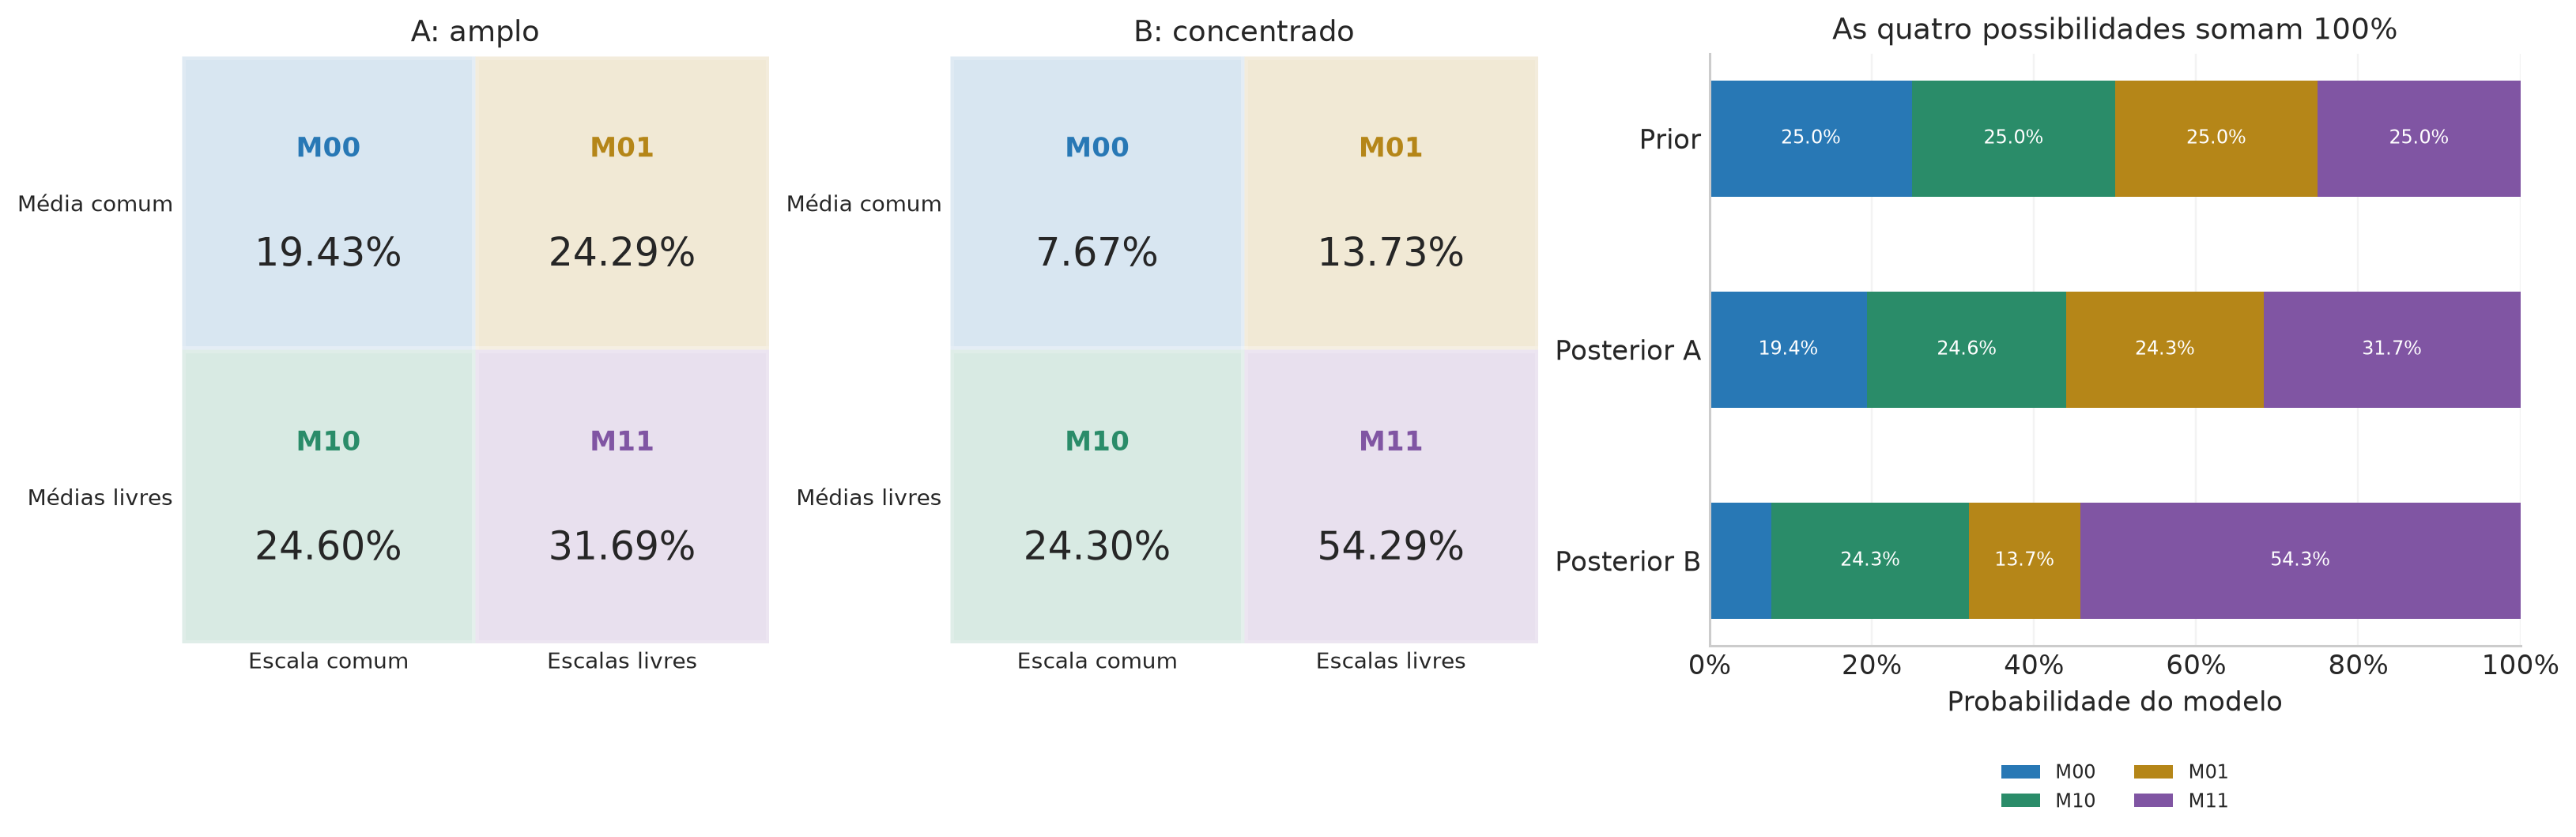

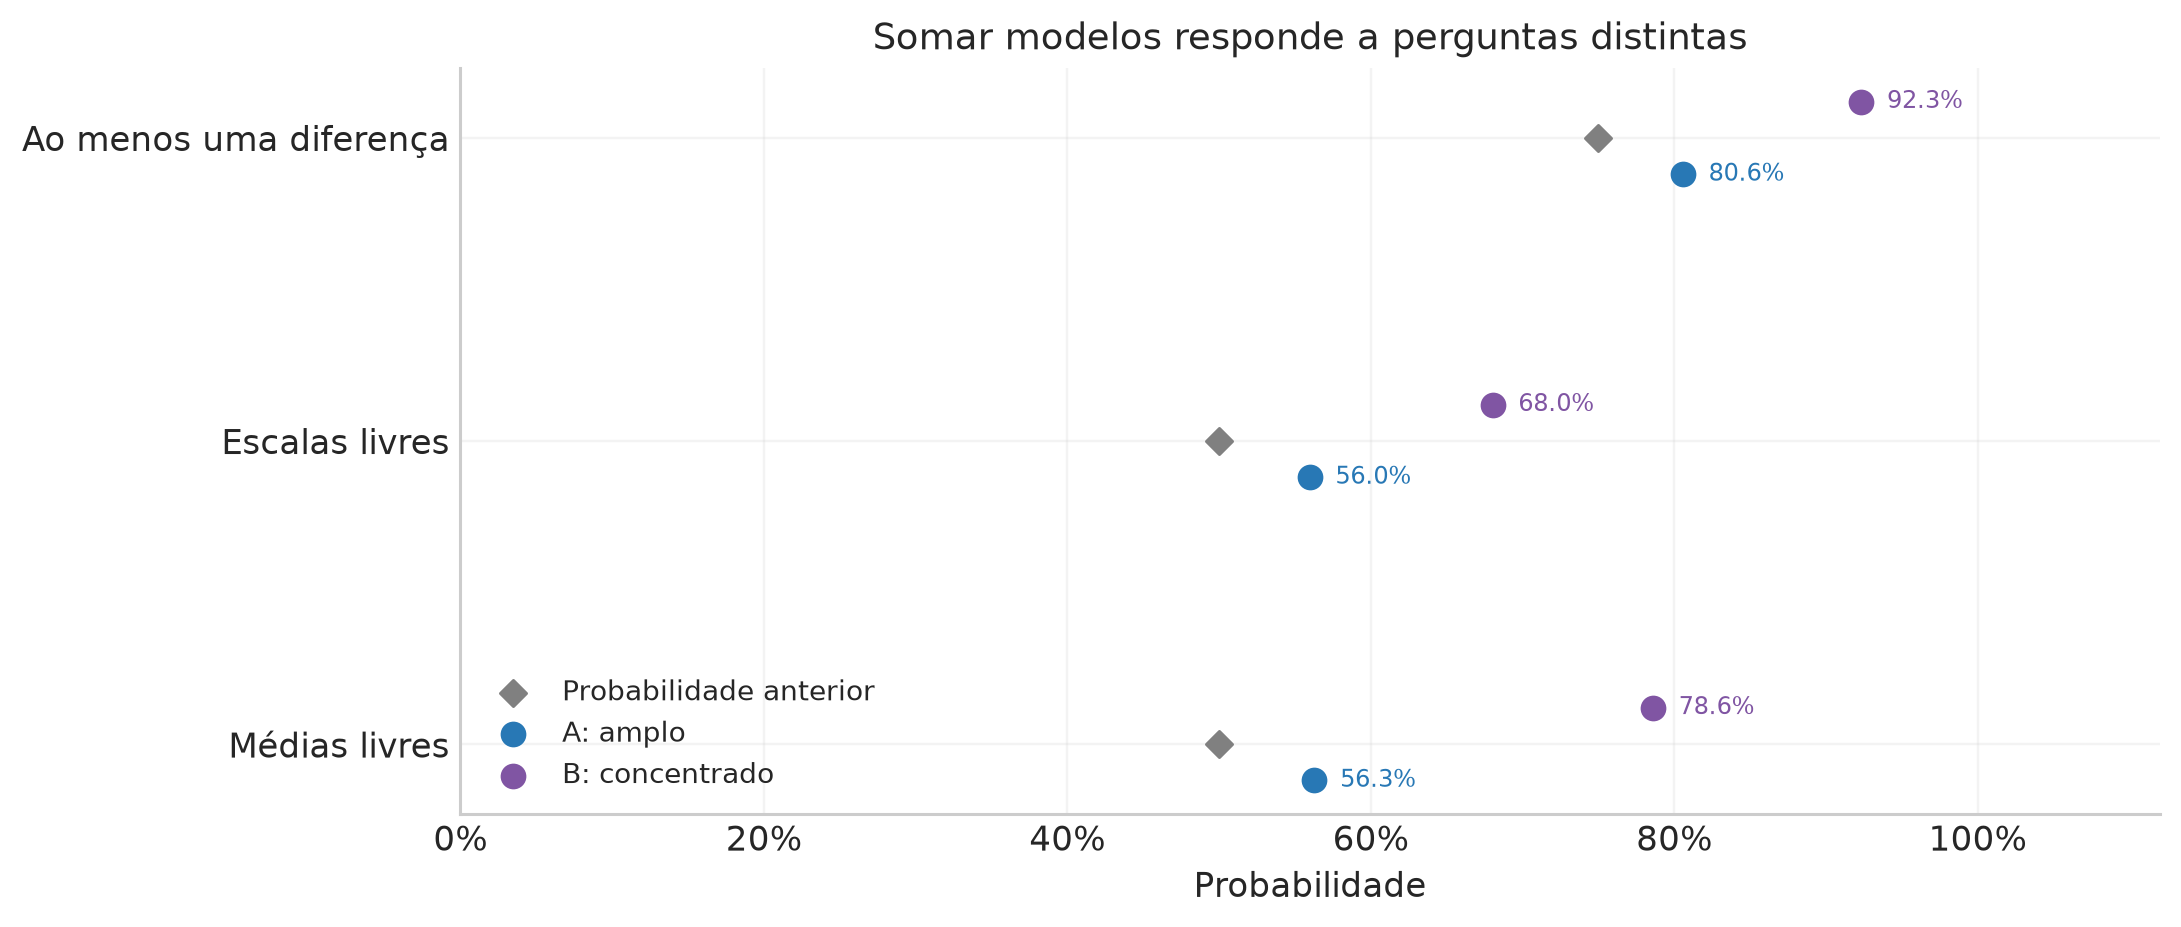

In [15]:
fig,ax=plt.subplots(1,3,figsize=(14.7,4.7),layout="constrained",gridspec_kw={"width_ratios":[1,1,1.38]})
mapa_modelos=np.array([[0,2],[1,3]])  # Linha = médias; coluna = escalas.
for a,(nome,pp) in zip(ax[:2],q1_Ps.items()):
    for row in range(2):
        for col in range(2):
            k=mapa_modelos[row,col]
            a.add_patch(Rectangle((col,row),1,1,facecolor=CORES_MODELOS[k],alpha=.18,edgecolor="white",lw=3))
            a.text(col+.5,row+.32,["M00","M10","M01","M11"][k],ha="center",va="center",color=CORES_MODELOS[k],weight="bold")
            a.text(col+.5,row+.68,f"{100*pp[k]:.2f}%",ha="center",va="center",fontsize=16)
    a.set(xlim=(0,2),ylim=(2,0),xticks=[.5,1.5],xticklabels=["Escala comum","Escalas livres"],
          yticks=[.5,1.5],yticklabels=["Média comum","Médias livres"],title=nome)
    a.set_aspect("equal");a.grid(False);a.tick_params(length=0,labelsize=9)
    for spine in a.spines.values():spine.set_visible(False)
valores=np.vstack([q1_prior_modelos,*q1_Ps.values()])
base=np.zeros(3)
for k,cor in enumerate(CORES_MODELOS):
    ax[2].barh(np.arange(3),valores[:,k],left=base,color=cor,height=.55,label=["M00","M10","M01","M11"][k])
    for j,v in enumerate(valores[:,k]):
        if v>.10:ax[2].text(base[j]+v/2,j,f"{100*v:.1f}%",ha="center",va="center",color="white",fontsize=8)
    base+=valores[:,k]
ax[2].set(yticks=[0,1,2],yticklabels=["Prior","Posterior A","Posterior B"],xlim=(0,1),
          xlabel="Probabilidade do modelo",title="As quatro possibilidades somam 100%")
ax[2].invert_yaxis();ax[2].xaxis.set_major_formatter(PercentFormatter(1))
ax[2].legend(ncol=2,loc="upper center",bbox_to_anchor=(.5,-.17),fontsize=8)
figura(fig,"q1_extra_quatro_modelos")

fig,ax=plt.subplots(figsize=(9.8,4.1),layout="constrained")
q1_perguntas=["Médias livres","Escalas livres","Ao menos uma diferença"]
ax.scatter([.5,.5,.75],np.arange(3),marker="D",color="gray",label="Probabilidade anterior",zorder=3)
for desloc,(nome,pp),cor in zip([-.12,.12],q1_Ps.items(),[AZUL,ROXO]):
    vals=np.array([pp[1]+pp[3],pp[2]+pp[3],1-pp[0]])
    yy=np.arange(3)+desloc
    ax.scatter(vals,yy,s=55,color=cor,label=nome,zorder=4)
    for v,y in zip(vals,yy):ax.text(v+.017,y,f"{100*v:.1f}%",va="center",fontsize=8,color=cor)
ax.set(yticks=np.arange(3),yticklabels=q1_perguntas,xlim=(0,1.12),xlabel="Probabilidade",
       title="Somar modelos responde a perguntas distintas")
ax.xaxis.set_major_formatter(PercentFormatter(1));ax.legend(loc="lower left",fontsize=9)
figura(fig,"q1_extra_perguntas_e_priors")

In [16]:
# Interpretação calculada a partir das mesmas probabilidades mostradas nas figuras.
def q1_tex_cientifico(x):
    mantissa,expoente=f"{x:.8e}".split("e")
    return mantissa+r"\times10^{"+str(int(expoente))+"}"

for nome,pp in q1_Ps.items():
    k=int(np.argmax(pp))
    zz=q1_Zs[nome]
    display(Markdown(
        f"**Normalização no cenário {nome}:** como as priors dos modelos são iguais, "
        f"$\\sum_k Z_k={q1_tex_cientifico(zz.sum())}$ e "
        f"$P(M_{{00}}\\mid D)=\\frac{{{q1_tex_cientifico(zz[0])}}}"
        f"{{{q1_tex_cientifico(zz.sum())}}}={pp[0]:.8f}$. "
        f"Para médias livres, somamos ${pp[1]:.8f}+{pp[3]:.8f}={pp[1]+pp[3]:.8f}$; "
        f"para escalas livres, ${pp[2]:.8f}+{pp[3]:.8f}={pp[2]+pp[3]:.8f}$. "
        "Os outros modelos são normalizados pelo mesmo denominador."
    ))
    display(Markdown(
        f"No cenário **{nome}**, o maior peso individual é de "
        f"**{['M00','M10','M01','M11'][k]}**, com **{100*pp[k]:.2f}%**. "
        f"Somando os modelos, a probabilidade de médias livres é "
        f"**{100*(pp[1]+pp[3]):.2f}%**, e a de escalas livres é "
        f"**{100*(pp[2]+pp[3]):.2f}%**, condicionadas às priors declaradas."
    ))

**Normalização no cenário A: amplo:** como as priors dos modelos são iguais, $\sum_k Z_k=4.40260952\times10^{-21}$ e $P(M_{00}\mid D)=\frac{8.55377185\times10^{-22}}{4.40260952\times10^{-21}}=0.19428868$. Para médias livres, somamos $0.24596544+0.31689578=0.56286122$; para escalas livres, $0.24285011+0.31689578=0.55974589$. Os outros modelos são normalizados pelo mesmo denominador.

No cenário **A: amplo**, o maior peso individual é de **M11**, com **31.69%**. Somando os modelos, a probabilidade de médias livres é **56.29%**, e a de escalas livres é **55.97%**, condicionadas às priors declaradas.

**Normalização no cenário B: concentrado:** como as priors dos modelos são iguais, $\sum_k Z_k=7.73659681\times10^{-20}$ e $P(M_{00}\mid D)=\frac{5.93165203\times10^{-21}}{7.73659681\times10^{-20}}=0.07667004$. Para médias livres, somamos $0.24304196+0.54294562=0.78598758$; para escalas livres, $0.13734238+0.54294562=0.68028800$. Os outros modelos são normalizados pelo mesmo denominador.

No cenário **B: concentrado**, o maior peso individual é de **M11**, com **54.29%**. Somando os modelos, a probabilidade de médias livres é **78.60%**, e a de escalas livres é **68.03%**, condicionadas às priors declaradas.

### Interpretando a extensão e sua relação com os testes

Os dois cenários usam os mesmos dados e as mesmas likelihoods. Mudam os intervalos de prior e seus fatores de normalização. Modelos com parâmetros adicionais distribuem suas previsões sobre mais possibilidades; a evidência faz a média dessas previsões. A melhora que eles obtêm em algumas regiões precisa compensar o peso de regiões que ajustam pior.

No cenário B, as fronteiras também mudam: por exemplo, médias acima de 12 ppm deixam de ser permitidas. Assim, a alteração das probabilidades não pode ser atribuída apenas a um fator abstrato de volume; a truncagem da região que contribui para as integrais também participa. Por isso mantivemos os termos de CDF nas integrais analíticas.

O gráfico de quatro cores responde à pergunta “quanto pesa cada modelo dentro deste conjunto e destas priors?”. Os testes anteriores respondem à pergunta “quão extremos seriam os resultados observados sob determinada hipótese nula?”. Não há identidade entre $1-p_F$ e a probabilidade de escalas livres, nem entre $1-p_p$ ou $1-p_W$ e a probabilidade de médias livres.

Também precisamos respeitar a diferença de condicionamento: o teste de (c) assume escala comum em todos os casos; a probabilidade agregada de médias livres soma modelos com escalas comuns **e** livres. Mesmo a comparação bayesiana restrita a $M_{10}$ versus $M_{00}$ ainda depende das priors e das evidências; ela não se obtém convertendo o valor-p de (c).

Essa extensão dá a interpretação probabilística que o gráfico sugerido pede, preservando o significado dos resultados frequentistas que constituem a resposta da questão.